In [1]:
!pip -q install timm scikit-learn pandas matplotlib tqdm pillow huggingface_hub


In [2]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)
print("Drive mounted.")

Mounted at /content/drive
Drive mounted.


In [3]:
import os, zipfile, shutil
from google.colab import files

print("Upload your stage3_local.zip file:")
uploaded = files.upload()

ZIP_NAME = list(uploaded.keys())[0]
EXTRACT_TO = "/content"

print(f"\nExtracting {ZIP_NAME} to {EXTRACT_TO}...")
with zipfile.ZipFile(ZIP_NAME, "r") as z:
    z.extractall(EXTRACT_TO)


STAGE3_LOCAL = "/content/stage3_local"
if os.path.exists(STAGE3_LOCAL):
    print(f"stage3_local found at: {STAGE3_LOCAL}")
    for root, dirs, files_list in os.walk(STAGE3_LOCAL):
        level = root.replace(STAGE3_LOCAL, "").count(os.sep)
        if level < 2:
            indent = "  " * level
            print(f"{indent}{os.path.basename(root)}/")
            if level < 1:
                subindent = "  " * (level + 1)
                for f in files_list[:5]:
                    print(f"{subindent}{f}")
else:
    raise RuntimeError("stage3_local not found after extraction. Check zip structure.")

Upload your stage3_local.zip file:


Saving stage3_local.zip to stage3_local.zip

Extracting stage3_local.zip to /content...
stage3_local found at: /content/stage3_local
stage3_local/
  results/
  weights/
  dr2015_structured/


In [4]:
import os, glob
import pandas as pd


STAGE3_LOCAL = "/content/stage3_local"
DR_OUT_DIR   = STAGE3_LOCAL

REQUIRED_STAGE3_COLUMNS = {"img_path", "label", "stage3_mask_path"}

csv_candidates = [
    c for c in glob.glob(os.path.join(STAGE3_LOCAL, "**", "*.csv"), recursive=True)
    if "results" not in c.lower()
]

print("CSV files found:")
for c in csv_candidates:
    print(f"  {c}")

stage3_csv = None

for c in csv_candidates:
    try:
        columns = set(pd.read_csv(c, nrows=0).columns)
    except Exception:
        continue

    if REQUIRED_STAGE3_COLUMNS.issubset(columns):
        stage3_csv = c
        break

if stage3_csv is None:
    raise RuntimeError(
        "No CSV with img_path, label, and stage3_mask_path was found in stage3_local."
    )

df = pd.read_csv(stage3_csv)

print(f"\nLoaded Stage 3 CSV: {stage3_csv}")
print(f"Rows: {len(df)}")
print(f"Columns: {list(df.columns)}")

print(
    df[
        ["img_path", "label", "stage3_mask_path"]
    ].head(3)
)

CSV files found:
  /content/stage3_local/dr2015_structured/dr2015_linked_stage1_stage2_stage3.csv
  /content/stage3_local/dr2015_structured/stage3_masks/stage3_mask_paths.csv
  /content/stage3_local/dr2015_structured/stage2_masks/stage2_mask_paths.csv

Loaded Stage 3 CSV: /content/stage3_local/dr2015_structured/dr2015_linked_stage1_stage2_stage3.csv
Rows: 35126
Columns: ['img_path', 'label', 'stage2_mask_path', 'stage3_mask_path']
                                            img_path  label  \
0  /content/drive/MyDrive/Dataset_extracted/color...      1   
1  /content/drive/MyDrive/Dataset_extracted/color...      1   
2  /content/drive/MyDrive/Dataset_extracted/color...      1   

                                    stage3_mask_path  
0  /content/stage3_local/dr2015_structured/stage3...  
1  /content/stage3_local/dr2015_structured/stage3...  
2  /content/stage3_local/dr2015_structured/stage3...  


In [5]:
import os
import gc
import copy
import shutil
import random

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import timm
import matplotlib.pyplot as plt

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score,
    precision_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    roc_auc_score
)
from sklearn.preprocessing import label_binarize


device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

AMP_DEVICE = (
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)


SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)

random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

print(f"Seed fixed: {SEED}")


STAGE3_SIZE = 384
STAGE3_BATCH = 64
STAGE3_NUM_WORKERS = 8

PIN_MEMORY = torch.cuda.is_available()

STAGE3_LOCAL = "/content/stage3_local"

RESULTS_DIR = os.path.join(
    STAGE3_LOCAL,
    "results"
)

os.makedirs(
    RESULTS_DIR,
    exist_ok=True
)

CLASS_NAMES = [
    "no_dr",
    "mild",
    "moderate",
    "severe",
    "proliferative_dr"
]

num_classes = len(CLASS_NAMES)

print(f"Results dir       : {RESULTS_DIR}")
print(f"Classes           : {CLASS_NAMES}")
print(f"Image size        : {STAGE3_SIZE}")

Device: cuda
Seed fixed: 42
Results dir       : /content/stage3_local/results
Classes           : ['no_dr', 'mild', 'moderate', 'severe', 'proliferative_dr']
Image size        : 384


In [6]:
pth_files = []
for root, dirs, files in os.walk("/content"):
    for f in files:
        if f.endswith(".pth"):
            pth_files.append(os.path.join(root, f))

print("Found .pth files:")
for i, p in enumerate(pth_files):
    print(f"  {i}: {p}")

if len(pth_files) == 0:
    print("No .pth files found.")

Found .pth files:
  0: /content/drive/MyDrive/DR_Project/stage3_stage2_masks_B1_B5_comparison/stage2_masks_B1_best.pth
  1: /content/drive/MyDrive/DR_Project/stage3_stage2_masks_B1_B5_comparison/stage2_masks_B2_best.pth
  2: /content/drive/MyDrive/DR_Project/stage3_stage2_masks_B1_B5_comparison/stage2_masks_B3_best.pth
  3: /content/drive/MyDrive/DR_Project/stage3_stage2_masks_B1_B5_comparison/stage2_masks_B4_best.pth
  4: /content/drive/MyDrive/DR_Project/stage3_stage2_masks_B1_B5_comparison/stage2_masks_B5_best.pth
  5: /content/drive/MyDrive/DR_Project/RVS_normal_split_separate/attention_unet_best.pth
  6: /content/drive/MyDrive/DR_Project/RVS_normal_split_separate/recursive_refinement_results/recursive_refinement_best.pth
  7: /content/drive/MyDrive/DR_Project/stage1/weights/stage1_original_fixed_best_dr_b0.pth
  8: /content/drive/MyDrive/DR_Project/stage2/weights/stage2_attunet_best.pth
  9: /content/drive/MyDrive/DR_Project/stage2/augmented_validation_experiment/stage2_paired_aug

In [7]:
STAGE1_W = "/content/drive/MyDrive/DR_Project/stage1/weights/stage1_original_fixed_best_dr_b0.pth"



stage1 = timm.create_model(
    "tf_efficientnet_b0.ns_jft_in1k",
    pretrained=False,
    num_classes=num_classes
)

stage1.load_state_dict(torch.load(STAGE1_W, map_location=device))
stage1 = stage1.to(device)
stage1.eval()

for p in stage1.parameters():
    p.requires_grad = False

print("Stage1 loaded")

Stage1 loaded


In [9]:
import os
import shutil
import time

from concurrent.futures import ThreadPoolExecutor, as_completed
from tqdm.auto import tqdm


DRIVE_IMAGE_ROOT = (
    "/content/drive/MyDrive/"
    "Dataset/colored_images/colored_images"
)

LOCAL_IMAGE_ROOT = "/content/dr_images"

COPY_COMPLETE_FILE = "/content/.dr_images_copy_complete"

MAX_WORKERS = 8
MAX_RETRIES = 5


os.makedirs(
    LOCAL_IMAGE_ROOT,
    exist_ok=True
)


if not os.path.exists(DRIVE_IMAGE_ROOT):
    raise RuntimeError(
        f"Google Drive folder not found:\n{DRIVE_IMAGE_ROOT}"
    )


print("Scanning files...")


all_files = []

for root, dirs, filenames in os.walk(
    DRIVE_IMAGE_ROOT
):

    for filename in filenames:

        src = os.path.join(
            root,
            filename
        )

        relative_path = os.path.relpath(
            src,
            DRIVE_IMAGE_ROOT
        )

        dst = os.path.join(
            LOCAL_IMAGE_ROOT,
            relative_path
        )

        all_files.append(
            (src, dst)
        )


print(
    f"Total files: {len(all_files):,}"
)


remaining_files = []


for src, dst in tqdm(
    all_files,
    desc="Checking existing files",
    unit="file"
):

    try:

        if os.path.exists(dst):

            src_size = os.path.getsize(src)
            dst_size = os.path.getsize(dst)

            if src_size == dst_size:
                continue

            os.remove(dst)

        remaining_files.append(
            (src, dst)
        )

    except Exception:

        remaining_files.append(
            (src, dst)
        )


already_complete = (
    len(all_files)
    -
    len(remaining_files)
)


print(
    f"\nAlready copied correctly: {already_complete:,}"
)

print(
    f"Remaining to copy: {len(remaining_files):,}"
)


def copy_with_retry(item):

    src, dst = item

    os.makedirs(
        os.path.dirname(dst),
        exist_ok=True
    )

    last_error = None


    for attempt in range(
        1,
        MAX_RETRIES + 1
    ):

        try:

            if os.path.exists(dst):

                try:

                    if (
                        os.path.getsize(src)
                        ==
                        os.path.getsize(dst)
                    ):
                        return True, src, None

                except Exception:
                    pass


                try:
                    os.remove(dst)
                except Exception:
                    pass


            shutil.copyfile(
                src,
                dst
            )


            if (
                os.path.getsize(src)
                !=
                os.path.getsize(dst)
            ):

                raise IOError(
                    "Copied file size does not match source."
                )


            return True, src, None


        except Exception as e:

            last_error = e


            try:
                if os.path.exists(dst):
                    os.remove(dst)
            except Exception:
                pass


            time.sleep(
                min(
                    attempt * 2,
                    10
                )
            )


    return (
        False,
        src,
        str(last_error)
    )


errors = []


with ThreadPoolExecutor(
    max_workers=MAX_WORKERS
) as executor:

    futures = [
        executor.submit(
            copy_with_retry,
            item
        )
        for item in remaining_files
    ]


    for future in tqdm(
        as_completed(futures),
        total=len(futures),
        desc="Copying DR images",
        unit="file"
    ):

        success, src, error = (
            future.result()
        )


        if not success:

            errors.append(
                {
                    "file": src,
                    "error": error
                }
            )


print("\n" + "=" * 70)
print("COPY CHECK")
print("=" * 70)


if errors:

    print(
        f"Files still failed after retries: "
        f"{len(errors):,}"
    )

    print("\nFirst few failed files:")

    for item in errors[:10]:

        print(
            item["file"]
        )

        print(
            item["error"]
        )

    print(
        "\nRun this same cell again. "
        "It will skip all successfully copied files "
        "and retry only the remaining files."
    )

else:

    with open(
        COPY_COMPLETE_FILE,
        "w"
    ) as f:

        f.write("complete")


    print(
        "All DR images copied successfully."
    )

    print(
        "Local folder:",
        LOCAL_IMAGE_ROOT
    )

Scanning files...
Total files: 35,126


Checking existing files:   0%|          | 0/35126 [00:00<?, ?file/s]


Already copied correctly: 0
Remaining to copy: 35,126


Copying DR images:   0%|          | 0/35126 [00:00<?, ?file/s]


COPY CHECK
All DR images copied successfully.
Local folder: /content/dr_images


In [10]:
gc.collect()
torch.cuda.empty_cache()

In [11]:
import os
import glob
import pandas as pd

STAGE3_LOCAL = "/content/stage3_local"

REQUIRED_STAGE3_COLUMNS = {
    "img_path",
    "label",
    "stage3_mask_path"
}

csv_candidates = glob.glob(
    os.path.join(
        STAGE3_LOCAL,
        "**",
        "*.csv"
    ),
    recursive=True
)

stage3_csv = None

for c in csv_candidates:

    try:
        columns = set(
            pd.read_csv(
                c,
                nrows=0
            ).columns
        )
    except Exception:
        continue

    if REQUIRED_STAGE3_COLUMNS.issubset(columns):
        stage3_csv = c
        break


if stage3_csv is None:
    raise RuntimeError(
        "Stage3 CSV not found inside /content/stage3_local"
    )


df_stage3 = pd.read_csv(
    stage3_csv
)


DRIVE_IMAGE_ROOT = (
    "/content/drive/MyDrive/"
    "Dataset_extracted/colored_images/colored_images"
)

LOCAL_IMAGE_ROOT = "/content/dr_images"


def convert_image_path_to_local(path):

    path = str(path).strip()

    if path.startswith(DRIVE_IMAGE_ROOT):

        relative_path = os.path.relpath(
            path,
            DRIVE_IMAGE_ROOT
        )

        return os.path.join(
            LOCAL_IMAGE_ROOT,
            relative_path
        )

    return path


df_stage3["img_path"] = (
    df_stage3["img_path"]
    .apply(convert_image_path_to_local)
)


df_stage3["stage3_mask_path"] = (
    df_stage3["stage3_mask_path"]
    .fillna("")
    .astype(str)
    .str.strip()
)


df_stage3 = df_stage3[
    df_stage3["img_path"].apply(os.path.exists)
    &
    df_stage3["stage3_mask_path"].apply(os.path.exists)
].copy()


df_stage3["label"] = (
    df_stage3["label"]
    .astype(int)
)


df_stage3["basename"] = (
    df_stage3["img_path"]
    .apply(
        lambda p: os.path.basename(str(p))
    )
)


df_stage3 = df_stage3.reset_index(
    drop=True
)


print("Rows:", len(df_stage3))
print(df_stage3.head())

Rows: 35126
                                  img_path  label  \
0  /content/dr_images/Mild/34350_right.png      1   
1  /content/dr_images/Mild/34364_right.png      1   
2   /content/dr_images/Mild/34368_left.png      1   
3   /content/dr_images/Mild/34382_left.png      1   
4   /content/dr_images/Mild/34405_left.png      1   

                                    stage2_mask_path  \
0  /content/stage3_local/dr2015_structured/stage2...   
1  /content/stage3_local/dr2015_structured/stage2...   
2  /content/stage3_local/dr2015_structured/stage2...   
3  /content/stage3_local/dr2015_structured/stage2...   
4  /content/stage3_local/dr2015_structured/stage2...   

                                    stage3_mask_path         basename  
0  /content/stage3_local/dr2015_structured/stage3...  34350_right.png  
1  /content/stage3_local/dr2015_structured/stage3...  34364_right.png  
2  /content/stage3_local/dr2015_structured/stage3...   34368_left.png  
3  /content/stage3_local/dr2015_structured/s

In [12]:
SPLIT_DIR = "/content/drive/MyDrive/DR_Project/splits"

def load_names(filename):
    path = os.path.join(
        SPLIT_DIR,
        filename
    )

    if not os.path.exists(path):
        raise FileNotFoundError(path)

    with open(path, "r") as f:
        return set(
            line.strip()
            for line in f
            if line.strip()
        )

stage1_train_names = load_names(
    "stage1_train_names.txt"
)

stage1_val_names = load_names(
    "stage1_val_names.txt"
)

stage1_test_names = load_names(
    "stage1_test_names.txt"
)

df_stage3["basename"] = (
    df_stage3["img_path"]
    .apply(
        lambda p: os.path.basename(str(p))
    )
)

available_names = set(
    df_stage3["basename"].astype(str)
)

missing_train = (
    stage1_train_names
    -
    available_names
)

missing_val = (
    stage1_val_names
    -
    available_names
)

missing_test = (
    stage1_test_names
    -
    available_names
)

if missing_train:
    raise RuntimeError(
        f"{len(missing_train)} Stage1 train images "
        "are missing from Stage3 data."
    )

if missing_val:
    raise RuntimeError(
        f"{len(missing_val)} Stage1 validation images "
        "are missing from Stage3 data."
    )

if missing_test:
    raise RuntimeError(
        f"{len(missing_test)} Stage1 test images "
        "are missing from Stage3 data."
    )

if stage1_train_names & stage1_val_names:
    raise RuntimeError(
        "Stage1 train and validation overlap."
    )

if stage1_train_names & stage1_test_names:
    raise RuntimeError(
        "Stage1 train and test overlap."
    )

if stage1_val_names & stage1_test_names:
    raise RuntimeError(
        "Stage1 validation and test overlap."
    )

train_df = (
    df_stage3[
        df_stage3["basename"].isin(
            stage1_train_names
        )
    ]
    .copy()
    .reset_index(drop=True)
)

val_df = (
    df_stage3[
        df_stage3["basename"].isin(
            stage1_val_names
        )
    ]
    .copy()
    .reset_index(drop=True)
)

test_df = (
    df_stage3[
        df_stage3["basename"].isin(
            stage1_test_names
        )
    ]
    .copy()
    .reset_index(drop=True)
)

train_names = set(
    train_df["basename"].astype(str)
)

val_names = set(
    val_df["basename"].astype(str)
)

test_names = set(
    test_df["basename"].astype(str)
)

if train_names != stage1_train_names:
    raise RuntimeError(
        "Stage3 train images do not exactly "
        "match Stage1 train images."
    )

if val_names != stage1_val_names:
    raise RuntimeError(
        "Stage3 validation images do not exactly "
        "match Stage1 validation images."
    )

if test_names != stage1_test_names:
    raise RuntimeError(
        "Stage3 test images do not exactly "
        "match Stage1 test images."
    )

assigned_names = (
    train_names
    |
    val_names
    |
    test_names
)

if assigned_names != available_names:
    raise RuntimeError(
        "Stage1 split files do not exactly cover "
        "the available Stage3 dataset."
    )

print("=" * 70)
print("STAGE1 / STAGE3 IDENTICAL SPLIT")
print("=" * 70)

print(
    "Total dataset :",
    len(df_stage3)
)

print(
    "Train         :",
    len(train_df)
)

print(
    "Validation    :",
    len(val_df)
)

print(
    "Test          :",
    len(test_df)
)

print()
print(
    "Train-Val overlap :",
    len(train_names & val_names)
)

print(
    "Train-Test overlap:",
    len(train_names & test_names)
)

print(
    "Val-Test overlap  :",
    len(val_names & test_names)
)

print()
print(
    "Same Stage1/Stage3 train:",
    train_names == stage1_train_names
)

print(
    "Same Stage1/Stage3 val  :",
    val_names == stage1_val_names
)

print(
    "Same Stage1/Stage3 test :",
    test_names == stage1_test_names
)

print()
print("Train class counts:")

train_counts = (
    train_df["label"]
    .value_counts()
    .sort_index()
)

for i, class_name in enumerate(
    CLASS_NAMES
):
    print(
        f"{class_name:<22}: "
        f"{int(train_counts.get(i, 0)):>5}"
    )

print()
print("Validation class counts:")

val_counts = (
    val_df["label"]
    .value_counts()
    .sort_index()
)

for i, class_name in enumerate(
    CLASS_NAMES
):
    print(
        f"{class_name:<22}: "
        f"{int(val_counts.get(i, 0)):>5}"
    )

print()
print("Test class counts:")

test_counts = (
    test_df["label"]
    .value_counts()
    .sort_index()
)

for i, class_name in enumerate(
    CLASS_NAMES
):
    print(
        f"{class_name:<22}: "
        f"{int(test_counts.get(i, 0)):>5}"
    )

STAGE1 / STAGE3 IDENTICAL SPLIT
Total dataset : 35126
Train         : 24588
Validation    : 5269
Test          : 5269

Train-Val overlap : 0
Train-Test overlap: 0
Val-Test overlap  : 0

Same Stage1/Stage3 train: True
Same Stage1/Stage3 val  : True
Same Stage1/Stage3 test : True

Train class counts:
no_dr                 : 18067
mild                  :  1710
moderate              :  3704
severe                :   611
proliferative_dr      :   496

Validation class counts:
no_dr                 :  3871
mild                  :   367
moderate              :   794
severe                :   131
proliferative_dr      :   106

Test class counts:
no_dr                 :  3872
mild                  :   366
moderate              :   794
severe                :   131
proliferative_dr      :   106


In [15]:
# DATASET + DATALOADERS

import random as _random
import torchvision.transforms.functional as TF


_MEAN = np.array(
    [0.485, 0.456, 0.406],
    dtype=np.float32
)

_STD = np.array(
    [0.229, 0.224, 0.225],
    dtype=np.float32
)


class DRStage3Dataset(Dataset):

    def __init__(
        self,
        df,
        size=384,
        augment=False,
        zero_mask=False
    ):
        self.df = df.reset_index(drop=True)
        self.size = size
        self.augment = augment
        self.zero_mask = bool(zero_mask)


    def __len__(self):
        return len(self.df)


    def _load_rgb(self, path):

        img = Image.open(path).convert("RGB")

        img = img.resize(
            (self.size, self.size),
            Image.BILINEAR
        )

        return img


    def _load_mask(self, path):

        mask = Image.open(path).convert("L")

        mask = mask.resize(
            (self.size, self.size),
            Image.NEAREST
        )

        return mask


    def _augment(
        self,
        img_pil,
        mask_pil
    ):

        # Horizontal flip
        if _random.random() > 0.5:

            img_pil = TF.hflip(img_pil)

            mask_pil = TF.hflip(mask_pil)


        # Vertical flip
        if _random.random() > 0.5:

            img_pil = TF.vflip(img_pil)

            mask_pil = TF.vflip(mask_pil)


        # Rotation
        k = _random.randint(0, 3)

        if k > 0:

            img_pil = TF.rotate(
                img_pil,
                k * 90
            )

            mask_pil = TF.rotate(
                mask_pil,
                k * 90
            )


        # Brightness
        if _random.random() > 0.4:

            img_pil = TF.adjust_brightness(
                img_pil,
                1.0 + _random.uniform(-0.3, 0.3)
            )


        # Contrast
        if _random.random() > 0.4:

            img_pil = TF.adjust_contrast(
                img_pil,
                1.0 + _random.uniform(-0.3, 0.3)
            )


        # Saturation
        if _random.random() > 0.4:

            img_pil = TF.adjust_saturation(
                img_pil,
                1.0 + _random.uniform(-0.3, 0.3)
            )


        return img_pil, mask_pil


    def _to_tensor(
        self,
        img_pil,
        mask_pil
    ):

        # RGB image
        arr = (
            np.array(img_pil)
            .astype(np.float32)
            / 255.0
        )

        arr = (
            arr - _MEAN
        ) / _STD


        rgb = torch.tensor(
            np.transpose(
                arr,
                (2, 0, 1)
            ),
            dtype=torch.float32
        )


        # Stage 3 mask
        m = (
            np.array(mask_pil)
            .astype(np.float32)
            / 255.0
            > 0.5
        ).astype(np.float32)


        mask = torch.tensor(
            m[None, :, :],
            dtype=torch.float32
        )


        return rgb, mask


    def __getitem__(self, idx):

        row = self.df.iloc[idx]


        # Original RGB image
        img_pil = self._load_rgb(
            str(row["img_path"])
        )


        # STRICTLY STAGE 3 MASK
        mask_pil = self._load_mask(
            str(row["stage3_mask_path"])
        )


        label = int(
            row["label"]
        )


        if self.augment:

            img_pil, mask_pil = self._augment(
                img_pil,
                mask_pil
            )


        rgb, mask = self._to_tensor(
            img_pil,
            mask_pil
        )

        # every vessel mask is zero-valued.
        # This happens for train, validation AND test dataset
        if self.zero_mask:
            mask = torch.zeros_like(mask)

        return rgb, mask, label


# --------------------------------------------------
# OVERSAMPLING
# --------------------------------------------------

# Mild 2x, severe 2x, PDR 2x
mild_df = train_df[
    train_df["label"] == 1
]

severe_df = train_df[
    train_df["label"] == 3
]

pdr_df = train_df[
    train_df["label"] == 4
]


train_df_balanced = pd.concat(
    [
        train_df,
        mild_df,
        severe_df,
        pdr_df,
    ],
    ignore_index=True
)


print(
    "Balanced train class counts:"
)

vc = (
    train_df_balanced["label"]
    .value_counts()
    .sort_index()
)


for i, cn in enumerate(CLASS_NAMES):

    n = vc.get(i, 0)

    print(
        f"  {cn:<22}: {n:>5}"
    )


print(
    f"\nTrain original : "
    f"{len(train_df)}"
)

print(
    f"Train balanced : "
    f"{len(train_df_balanced)}"
)

print(
    f"Val            : "
    f"{len(val_df)}"
)

print(
    f"Test           : "
    f"{len(test_df)}"
)


# --------------------------------------------------
# DATASETS
# --------------------------------------------------

stage3_train_ds = DRStage3Dataset(
    train_df_balanced,
    size=STAGE3_SIZE,
    augment=True,
    zero_mask=True
)

stage3_val_ds = DRStage3Dataset(
    val_df,
    size=STAGE3_SIZE,
    augment=False,
    zero_mask=True
)

stage3_test_ds = DRStage3Dataset(
    test_df,
    size=STAGE3_SIZE,
    augment=False,
    zero_mask=True
)


# --------------------------------------------------
# DATALOADERS
# --------------------------------------------------

dr_train_loader = DataLoader(
    stage3_train_ds,
    batch_size=STAGE3_BATCH,
    shuffle=True,
    num_workers=STAGE3_NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    persistent_workers=True,
    prefetch_factor=2
)


dr_val_loader = DataLoader(
    stage3_val_ds,
    batch_size=STAGE3_BATCH,
    shuffle=False,
    num_workers=STAGE3_NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    persistent_workers=True,
    prefetch_factor=2
)


dr_test_loader = DataLoader(
    stage3_test_ds,
    batch_size=STAGE3_BATCH,
    shuffle=False,
    num_workers=STAGE3_NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    persistent_workers=True,
    prefetch_factor=2
)


print(
    f"\nTrain batches  : "
    f"{len(dr_train_loader)}"
)

print(
    f"Val batches    : "
    f"{len(dr_val_loader)}"
)

print(
    f"Test batches   : "
    f"{len(dr_test_loader)}"
)

Balanced train class counts:
  no_dr                 : 18067
  mild                  :  3420
  moderate              :  3704
  severe                :  1222
  proliferative_dr      :   992

Train original : 24588
Train balanced : 27405
Val            : 5269
Test           : 5269

Train batches  : 429
Val batches    : 83
Test batches   : 83


In [16]:
for split_name, ds in [
    ("train", stage3_train_ds),
    ("validation", stage3_val_ds),
    ("test", stage3_test_ds),
]:
    assert len(ds) > 0, f"{split_name}: empty dataset"
    rgb_example, mask_example, label_example = ds[0]
    assert rgb_example.shape == (3, STAGE3_SIZE, STAGE3_SIZE)
    assert mask_example.shape == (1, STAGE3_SIZE, STAGE3_SIZE)
    assert torch.count_nonzero(mask_example).item() == 0, (
        f"{split_name}: found nonzero values!"
    )
    print(f"{split_name}: {len(ds)} images; mask has only zeros. PASS")


real_mask_test_ds = DRStage3Dataset(
    test_df, size=STAGE3_SIZE, augment=False, zero_mask=False
)


train: 27405 images; mask has only zeros. PASS
validation: 5269 images; mask has only zeros. PASS
test: 5269 images; mask has only zeros. PASS


In [17]:
from huggingface_hub import logging as hf_logging

hf_logging.set_verbosity_error()

In [18]:
import numpy as np

import torch
import torch.nn as nn

import timm

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score,
    precision_score,
    roc_auc_score
)

from sklearn.preprocessing import label_binarize


RGB_SCALE = 0.75
MASK_SCALE = 1.25
DROP = 0.45


if "AMP_DEVICE" not in globals():

    AMP_DEVICE = (
        "cuda"
        if torch.cuda.is_available()
        else "cpu"
    )


def macro_auc(
    y_true,
    probabilities
):

    try:

        y_binary = label_binarize(
            y_true,
            classes=list(
                range(
                    num_classes
                )
            )
        )

        return roc_auc_score(
            y_binary,
            probabilities,
            average="macro",
            multi_class="ovr"
        )

    except Exception:

        return np.nan


class SEBlock(nn.Module):

    def __init__(
        self,
        in_dim,
        reduction=16
    ):

        super().__init__()

        hidden_dim = max(
            1,
            in_dim // reduction
        )

        self.fc = nn.Sequential(

            nn.Linear(
                in_dim,
                hidden_dim,
                bias=False
            ),

            nn.ReLU(
                inplace=True
            ),

            nn.Linear(
                hidden_dim,
                in_dim,
                bias=False
            ),

            nn.Sigmoid()
        )


    def forward(
        self,
        x
    ):

        weights = self.fc(
            x
        )

        return (
            x
            *
            weights
        )


class _MaskEncoderProxy:

    def __init__(
        self,
        model
    ):

        self.enc3 = (
            model.blocks[-2]
        )

        self.enc4 = (
            model.blocks[-1]
        )


class Stage3EfficientNetB0BxSE(nn.Module):

    def __init__(
        self,
        num_classes,
        stage1_weight_path,
        mask_model_name,
        mask_pretrained=True
    ):

        super().__init__()


        self.rgb_scale = (
            RGB_SCALE
        )

        self.mask_scale = (
            MASK_SCALE
        )

        self.mask_model_name = (
            mask_model_name
        )


        rgb_model = timm.create_model(
            "tf_efficientnet_b0.ns_jft_in1k",
            pretrained=False,
            num_classes=0,
            global_pool="avg"
        )


        stage1_state = torch.load(
            stage1_weight_path,
            map_location="cpu"
        )


        if (
            isinstance(
                stage1_state,
                dict
            )
            and
            "state_dict"
            in stage1_state
        ):

            stage1_state = (
                stage1_state[
                    "state_dict"
                ]
            )


        if (
            isinstance(
                stage1_state,
                dict
            )
            and
            "model_state_dict"
            in stage1_state
        ):

            stage1_state = (
                stage1_state[
                    "model_state_dict"
                ]
            )


        stage1_state = {

            key:
                value

            for (
                key,
                value
            )
            in stage1_state.items()

            if not key.startswith(
                "classifier"
            )
        }


        rgb_model.load_state_dict(
            stage1_state,
            strict=False
        )


        for parameter in (
            rgb_model.parameters()
        ):

            parameter.requires_grad = False


        self.rgb_branch = (
            rgb_model
        )


        mask_model = timm.create_model(
            mask_model_name,
            pretrained=mask_pretrained,
            num_classes=0,
            global_pool="avg"
        )


        old_conv = (
            mask_model.conv_stem
        )


        new_conv = nn.Conv2d(
            1,
            old_conv.out_channels,
            kernel_size=
                old_conv.kernel_size,
            stride=
                old_conv.stride,
            padding=
                old_conv.padding,
            dilation=
                old_conv.dilation,
            groups=
                old_conv.groups,
            bias=False
        )


        with torch.no_grad():

            new_conv.weight.copy_(
                old_conv.weight.mean(
                    dim=1,
                    keepdim=True
                )
            )


        mask_model.conv_stem = (
            new_conv
        )


        if hasattr(
            mask_model,
            "set_grad_checkpointing"
        ):

            try:

                mask_model.set_grad_checkpointing(
                    True
                )

            except Exception:

                pass


        self.mask_branch = (
            mask_model
        )


        self._mask_encoder_proxy = (
            _MaskEncoderProxy(
                mask_model
            )
        )


        self.RGB_DIM = int(
            rgb_model.num_features
        )


        self.MASK_DIM = int(
            mask_model.num_features
        )


        self.FUSE_DIM = (
            self.RGB_DIM
            +
            self.MASK_DIM
        )


        self.se = SEBlock(
            self.FUSE_DIM,
            reduction=16
        )


        self.head = nn.Sequential(

            nn.Dropout(
                DROP
            ),

            nn.Linear(
                self.FUSE_DIM,
                num_classes
            )
        )


    @property
    def mask_encoder(
        self
    ):

        return (
            self._mask_encoder_proxy
        )


    def _features(
        self,
        rgb,
        mask
    ):

        with torch.no_grad():

            rgb_features = (
                self.rgb_branch(
                    rgb
                )
            )

        mask_features = (
            self.mask_branch(
                mask
            )
        )


        rgb_features = (
            self.rgb_scale
            *
            rgb_features
        )


        mask_features = (
            self.mask_scale
            *
            mask_features
        )


        fused_features = torch.cat(
            [
                rgb_features,
                mask_features
            ],
            dim=1
        )


        attended_features = (
            self.se(
                fused_features
            )
        )


        return (
            attended_features,
            rgb_features,
            mask_features
        )


    def forward(
        self,
        rgb,
        mask
    ):

        (
            attended_features,
            _,
            _
        ) = self._features(
            rgb,
            mask
        )


        logits = self.head(
            attended_features
        )


        return logits


    def forward_with_parts(
        self,
        rgb,
        mask
    ):

        (
            attended_features,
            rgb_features,
            mask_features
        ) = self._features(
            rgb,
            mask
        )


        logits = self.head(
            attended_features
        )


        return (
            logits,
            mask_features
        )


    def forward_rgb_only(
        self,
        rgb,
        mask=None
    ):

        with torch.no_grad():

            rgb_features = (
                self.rgb_scale
                *
                self.rgb_branch(
                    rgb
                )
            )


        zero_mask_features = (
            torch.zeros(
                rgb_features.size(0),
                self.MASK_DIM,
                device=
                    rgb_features.device,
                dtype=
                    rgb_features.dtype
            )
        )


        fused = torch.cat(
            [
                rgb_features,
                zero_mask_features
            ],
            dim=1
        )


        attended = self.se(
            fused
        )


        return self.head(
            attended
        )


    def forward_mask_only(
        self,
        rgb,
        mask
    ):

        mask_features = (
            self.mask_scale
            *
            self.mask_branch(
                mask
            )
        )


        zero_rgb_features = (
            torch.zeros(
                mask_features.size(0),
                self.RGB_DIM,
                device=
                    mask_features.device,
                dtype=
                    mask_features.dtype
            )
        )


        fused = torch.cat(
            [
                zero_rgb_features,
                mask_features
            ],
            dim=1
        )


        attended = self.se(
            fused
        )


        return self.head(
            attended
        )


@torch.no_grad()
def evaluate(
    model,
    loader
):

    model.eval()


    labels_all = []

    predictions_all = []

    probabilities_all = []

    validation_losses = []


    for (
        rgb,
        mask,
        labels
    ) in loader:


        rgb = rgb.to(
            device,
            non_blocking=True
        )


        mask = mask.to(
            device,
            non_blocking=True
        )


        labels = labels.to(
            device,
            non_blocking=True
        )


        if torch.cuda.is_available():

            rgb = rgb.contiguous(
                memory_format=
                    torch.channels_last
            )


            mask = mask.contiguous(
                memory_format=
                    torch.channels_last
            )


        with torch.amp.autocast(
            device_type=
                AMP_DEVICE,
            enabled=
                torch.cuda.is_available()
        ):

            logits = model(
                rgb,
                mask
            )


            loss = criterion(
                logits,
                labels
            )


            probabilities = (
                torch.softmax(
                    logits,
                    dim=1
                )
            )


        validation_losses.append(
            float(
                loss
                .detach()
                .cpu()
                .item()
            )
        )


        labels_all.extend(
            labels
            .detach()
            .cpu()
            .numpy()
        )


        predictions_all.extend(
            logits
            .argmax(
                dim=1
            )
            .detach()
            .cpu()
            .numpy()
        )


        probabilities_all.extend(
            probabilities
            .detach()
            .cpu()
            .numpy()
        )


    labels_all = np.asarray(
        labels_all
    )


    predictions_all = np.asarray(
        predictions_all
    )


    probabilities_all = np.asarray(
        probabilities_all
    )


    accuracy = accuracy_score(
        labels_all,
        predictions_all
    )


    macro_f1 = f1_score(
        labels_all,
        predictions_all,
        average="macro",
        zero_division=0
    )


    weighted_f1 = f1_score(
        labels_all,
        predictions_all,
        average="weighted",
        zero_division=0
    )


    auc_value = macro_auc(
        labels_all,
        probabilities_all
    )


    recalls = recall_score(
        labels_all,
        predictions_all,
        average=None,
        labels=list(
            range(
                num_classes
            )
        ),
        zero_division=0
    )


    precisions = precision_score(
        labels_all,
        predictions_all,
        average=None,
        labels=list(
            range(
                num_classes
            )
        ),
        zero_division=0
    )


    return {

        "labels":
            labels_all,

        "preds":
            predictions_all,

        "probs":
            probabilities_all,

        "loss":
            float(
                np.mean(
                    validation_losses
                )
            ),

        "accuracy":
            accuracy,

        "macro_f1":
            macro_f1,

        "weighted_f1":
            weighted_f1,

        "macro_auc":
            auc_value,

        "recall":
            recalls,

        "precision":
            precisions
    }


print(
    "Stage3EfficientNetB0BxSE defined:",
    "Stage3EfficientNetB0BxSE"
    in globals()
)


print(
    "evaluate defined:",
    "evaluate"
    in globals()
)

Stage3EfficientNetB0BxSE defined: True
evaluate defined: True


In [19]:
import os
import gc
import math
import random
import shutil
import warnings

import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.optim as optim
import timm

from torch.utils.data import DataLoader

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score,
    precision_score,
    roc_auc_score
)

from sklearn.preprocessing import label_binarize
from tqdm.auto import tqdm

warnings.filterwarnings(
    "ignore",
    message="name."
)

try:
    from huggingface_hub import logging as hf_logging
    hf_logging.set_verbosity_error()
except Exception:
    pass

EPOCHS = 60
PATIENCE = 5
EFFECTIVE_BATCH = 64

LR = 1e-4
WEIGHT_DECAY = 1e-3

AUX_WEIGHT = 0.40
MASK_DROP_P = 0.10

SEED_COMPARE = 42

# Train both B3 and B4 zero-mask controls
MODELS = {
    "B3": "tf_efficientnet_b3.ns_jft_in1k",
    "B4": "tf_efficientnet_b4.ns_jft_in1k"
}

BATCH_BY_MODEL = {
    "B1": 32,
    "B2": 32,
    "B3": 16,
    "B4": 8,
    "B5": 8
}

if "FAST_NUM_WORKERS" not in globals():
    cpu_count = os.cpu_count() or 2
    FAST_NUM_WORKERS = min(
        4,
        max(
            2,
            cpu_count - 1
        )
    )

if "FAST_PIN_MEMORY" not in globals():
    FAST_PIN_MEMORY = torch.cuda.is_available()

if "USE_AMP" not in globals():
    USE_AMP = torch.cuda.is_available()

if "AMP_DEVICE" not in globals():
    AMP_DEVICE = (
        "cuda"
        if torch.cuda.is_available()
        else "cpu"
    )

required_items = [
    "stage3_train_ds",
    "stage3_val_ds",
    "Stage3EfficientNetB0BxSE",
    "device",
    "num_classes",
    "CLASS_NAMES",
    "STAGE1_W"
]

missing = [
    name
    for name in required_items
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Missing required variables: "
        + ", ".join(missing)
        + "\nRun your dataset/model setup cells first."
    )

def seed_all_compare():
    random.seed(SEED_COMPARE)
    np.random.seed(SEED_COMPARE)
    torch.manual_seed(SEED_COMPARE)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED_COMPARE)

DRIVE_COMPARE_DIR = (
    "/content/drive/MyDrive/DR_Project/"
    "stage3_B3SE_zero_mask_training_control"
)

LOCAL_COMPARE_DIR = (
    "/content/stage3_B3SE_zero_mask_training_control"
)

os.makedirs(
    DRIVE_COMPARE_DIR,
    exist_ok=True
)

os.makedirs(
    LOCAL_COMPARE_DIR,
    exist_ok=True
)

print("Drive comparison directory:")
print(DRIVE_COMPARE_DIR)

LOCAL_STAGE1_W = os.path.join(
    "/content",
    os.path.basename(STAGE1_W)
)

if not os.path.exists(LOCAL_STAGE1_W):
    shutil.copy2(
        STAGE1_W,
        LOCAL_STAGE1_W
    )

class_weights = torch.tensor(
    [
        0.65,
        2.20,
        1.15,
        2.20,
        1.80
    ],
    dtype=torch.float32,
    device=device
)

criterion = nn.CrossEntropyLoss(
    weight=class_weights,
    label_smoothing=0.05
)

aux_criterion = nn.CrossEntropyLoss(
    weight=class_weights,
    label_smoothing=0.05
)

def macro_auc_with_loss(
    y_true,
    probabilities
):
    try:
        y_binary = label_binarize(
            y_true,
            classes=list(
                range(num_classes)
            )
        )

        return float(
            roc_auc_score(
                y_binary,
                probabilities,
                average="macro",
                multi_class="ovr"
            )
        )

    except Exception:
        return float("nan")

@torch.no_grad()
def evaluate_with_loss(
    model,
    loader
):
    model.eval()

    labels_all = []
    predictions_all = []
    probabilities_all = []
    validation_losses = []

    for rgb, mask, labels in loader:
        rgb = rgb.to(
            device,
            non_blocking=True
        )

        mask = mask.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        if torch.cuda.is_available():
            rgb = rgb.contiguous(
                memory_format=torch.channels_last
            )

            mask = mask.contiguous(
                memory_format=torch.channels_last
            )

        with torch.amp.autocast(
            device_type=AMP_DEVICE,
            enabled=USE_AMP
        ):
            logits = model(
                rgb,
                mask
            )

            loss = criterion(
                logits,
                labels
            )

        probabilities = torch.softmax(
            logits,
            dim=1
        )

        predictions = logits.argmax(
            dim=1
        )

        validation_losses.append(
            float(
                loss.detach()
                .cpu()
                .item()
            )
        )

        labels_all.extend(
            labels.detach()
            .cpu()
            .numpy()
        )

        predictions_all.extend(
            predictions.detach()
            .cpu()
            .numpy()
        )

        probabilities_all.extend(
            probabilities.detach()
            .cpu()
            .numpy()
        )

    labels_all = np.asarray(
        labels_all
    )

    predictions_all = np.asarray(
        predictions_all
    )

    probabilities_all = np.asarray(
        probabilities_all
    )

    accuracy = accuracy_score(
        labels_all,
        predictions_all
    )

    macro_f1_value = f1_score(
        labels_all,
        predictions_all,
        average="macro",
        zero_division=0
    )

    weighted_f1_value = f1_score(
        labels_all,
        predictions_all,
        average="weighted",
        zero_division=0
    )

    macro_auc_value = macro_auc_with_loss(
        labels_all,
        probabilities_all
    )

    recalls = recall_score(
        labels_all,
        predictions_all,
        average=None,
        labels=list(
            range(num_classes)
        ),
        zero_division=0
    )

    precisions = precision_score(
        labels_all,
        predictions_all,
        average=None,
        labels=list(
            range(num_classes)
        ),
        zero_division=0
    )

    return {
        "labels": labels_all,
        "preds": predictions_all,
        "probs": probabilities_all,
        "loss": float(
            np.mean(
                validation_losses
            )
        ),
        "accuracy": float(accuracy),
        "macro_f1": float(macro_f1_value),
        "weighted_f1": float(weighted_f1_value),
        "macro_auc": float(macro_auc_value),
        "recall": recalls,
        "precision": precisions
    }

def make_train_val_loaders(
    batch_size
):
    common = {
        "num_workers": FAST_NUM_WORKERS,
        "pin_memory": FAST_PIN_MEMORY
    }

    if FAST_NUM_WORKERS > 0:
        common[
            "persistent_workers"
        ] = True

        common[
            "prefetch_factor"
        ] = 4

    generator = torch.Generator()

    generator.manual_seed(
        SEED_COMPARE
    )

    train_loader = DataLoader(
        stage3_train_ds,
        batch_size=batch_size,
        shuffle=True,
        generator=generator,
        **common
    )

    val_loader = DataLoader(
        stage3_val_ds,
        batch_size=batch_size,
        shuffle=False,
        **common
    )

    return (
        train_loader,
        val_loader
    )

def print_saved_training_history(
    short_name
):
    history_path = os.path.join(
        DRIVE_COMPARE_DIR,
        f"stage3_{short_name}_history.csv"
    )

    if not os.path.exists(
        history_path
    ):
        print(
            f"History not found for {short_name}."
        )

        return

    history_df = pd.read_csv(
        history_path
    )

    if len(history_df) == 0:
        print(
            f"History empty for {short_name}."
        )

        return

    print(
        "\n"
        + "=" * 90
    )

    print(
        f"SAVED TRAINING HISTORY: {short_name}"
    )

    print(
        "=" * 90
    )

    best_f1 = -1.0
    wait = 0

    for _, row in history_df.iterrows():
        epoch = int(
            row[
                "epoch"
            ]
        )

        val_f1 = float(
            row[
                "val_macro_f1"
            ]
        )

        print(
            f"{short_name} | "
            f"Epoch {epoch:02d}/{EPOCHS} | "
            f"Train Total Loss={float(row['train_loss']):.4f} | "
            f"Train Main Loss={float(row['train_main_loss']):.4f} | "
            f"Val Loss={float(row['val_loss']):.4f} | "
            f"Val Accuracy={float(row['val_accuracy']):.4f} | "
            f"Val Macro-F1={val_f1:.4f} | "
            f"Val AUROC={float(row['val_macro_auc']):.4f}"
        )

        if val_f1 > best_f1:
            best_f1 = val_f1
            wait = 0

            print(
                "Best validation Macro-F1 checkpoint saved."
            )

        else:
            wait += 1

            print(
                f"Early stopping patience: "
                f"{wait}/{PATIENCE}"
            )

            if wait >= PATIENCE:
                print(
                    f"{short_name}: Early stopping."
                )

                break

def history_completed(
    short_name
):
    history_path = os.path.join(
        DRIVE_COMPARE_DIR,
        f"stage3_{short_name}_history.csv"
    )

    if not os.path.exists(
        history_path
    ):
        return False

    try:
        history_df = pd.read_csv(
            history_path
        )

        if len(history_df) == 0:
            return False

        required_history_columns = {
            "train_main_loss",
            "val_loss"
        }

        if not required_history_columns.issubset(
            history_df.columns
        ):
            return False

        best_f1 = -1.0
        wait = 0

        for _, row in history_df.iterrows():
            current_f1 = float(
                row[
                    "val_macro_f1"
                ]
            )

            if current_f1 > best_f1:
                best_f1 = current_f1
                wait = 0

            else:
                wait += 1

            if wait >= PATIENCE:
                return True

        last_epoch = int(
            history_df.iloc[-1][
                "epoch"
            ]
        )

        if last_epoch >= EPOCHS:
            return True

        return False

    except Exception:
        return False

def train_one_model(
    short_name,
    timm_model_name
):
    seed_all_compare()

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    batch_size = BATCH_BY_MODEL[
        short_name
    ]

    accumulation_steps = max(
        1,
        math.ceil(
            EFFECTIVE_BATCH
            /
            batch_size
        )
    )

    train_loader, val_loader = (
        make_train_val_loaders(
            batch_size
        )
    )

    model = Stage3EfficientNetB0BxSE(
        num_classes,
        LOCAL_STAGE1_W,
        timm_model_name,
        mask_pretrained=True
    ).to(
        device
    )

    if torch.cuda.is_available():
        model = model.to(
            memory_format=torch.channels_last
        )

    aux_head = nn.Linear(
        model.MASK_DIM,
        num_classes
    ).to(
        device
    )

    optimizer = optim.AdamW(
        [
            {
                "params":
                    model.mask_branch.parameters(),
                "lr":
                    LR
            },
            {
                "params":
                    model.se.parameters(),
                "lr":
                    LR
            },
            {
                "params":
                    model.head.parameters(),
                "lr":
                    LR
            },
            {
                "params":
                    aux_head.parameters(),
                "lr":
                    LR
            }
        ],
        weight_decay=WEIGHT_DECAY
    )

    scheduler = (
        optim.lr_scheduler.CosineAnnealingLR(
            optimizer,
            T_max=EPOCHS,
            eta_min=1e-7
        )
    )

    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=USE_AMP
    )

    drive_checkpoint = os.path.join(
        DRIVE_COMPARE_DIR,
        f"stage3_{short_name}_best.pth"
    )

    drive_history = os.path.join(
        DRIVE_COMPARE_DIR,
        f"stage3_{short_name}_history.csv"
    )

    complete_marker = os.path.join(
        DRIVE_COMPARE_DIR,
        f"stage3_{short_name}_COMPLETE.txt"
    )

    best_val_macro_f1 = -1.0
    best_epoch = -1
    wait = 0
    history = []

    print(
        "\n"
        + "=" * 90
    )

    print(
        f"MODEL: {short_name}\n"
        f"EfficientNet: {timm_model_name}\n"
        f"Epochs: {EPOCHS}\n"
        f"Patience: {PATIENCE}"
    )

    print(
        "=" * 90
    )

    for epoch in range(
        1,
        EPOCHS + 1
    ):
        model.train()
        model.rgb_branch.eval()
        aux_head.train()

        optimizer.zero_grad(
            set_to_none=True
        )

        train_losses = []
        train_main_losses = []
        train_labels = []
        train_predictions = []

        train_pbar = tqdm(
            train_loader,
            total=len(
                train_loader
            ),
            desc=(
                f"{short_name} "
                f"Epoch {epoch:02d}/{EPOCHS}"
            ),
            unit="batch",
            dynamic_ncols=True,
            leave=True
        )

        for step, (
            rgb,
            mask,
            labels
        ) in enumerate(
            train_pbar,
            start=1
        ):
            rgb = rgb.to(
                device,
                non_blocking=True
            )

            mask = mask.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )

            if torch.cuda.is_available():
                rgb = rgb.contiguous(
                    memory_format=torch.channels_last
                )

                mask = mask.contiguous(
                    memory_format=torch.channels_last
                )

            if MASK_DROP_P > 0:
                keep = (
                    torch.rand(
                        mask.size(0),
                        1,
                        1,
                        1,
                        device=device
                    )
                    >
                    MASK_DROP_P
                ).float()

                mask_train = (
                    mask
                    *
                    keep
                )

            else:
                mask_train = mask

            with torch.amp.autocast(
                device_type=AMP_DEVICE,
                enabled=USE_AMP
            ):
                (
                    logits,
                    mask_features
                ) = model.forward_with_parts(
                    rgb,
                    mask_train
                )

                mask_logits = aux_head(
                    mask_features
                )

                main_loss = criterion(
                    logits,
                    labels
                )

                vessel_loss = aux_criterion(
                    mask_logits,
                    labels
                )

                total_loss = (
                    main_loss
                    +
                    AUX_WEIGHT
                    *
                    vessel_loss
                )

            scaler.scale(
                total_loss
                /
                accumulation_steps
            ).backward()

            should_update = (
                step
                %
                accumulation_steps
                ==
                0
                or
                step
                ==
                len(train_loader)
            )

            if should_update:
                scaler.unscale_(
                    optimizer
                )

                torch.nn.utils.clip_grad_norm_(
                    list(
                        model.mask_branch.parameters()
                    )
                    +
                    list(
                        model.se.parameters()
                    )
                    +
                    list(
                        model.head.parameters()
                    )
                    +
                    list(
                        aux_head.parameters()
                    ),
                    max_norm=5.0
                )

                scaler.step(
                    optimizer
                )

                scaler.update()

                optimizer.zero_grad(
                    set_to_none=True
                )

            train_losses.append(
                float(
                    total_loss.detach()
                    .cpu()
                    .item()
                )
            )

            train_main_losses.append(
                float(
                    main_loss.detach()
                    .cpu()
                    .item()
                )
            )

            train_labels.extend(
                labels.detach()
                .cpu()
                .numpy()
            )

            train_predictions.extend(
                logits.argmax(
                    dim=1
                )
                .detach()
                .cpu()
                .numpy()
            )

            train_pbar.set_postfix(
                total_loss=
                    f"{np.mean(train_losses):.4f}",
                main_loss=
                    f"{np.mean(train_main_losses):.4f}",
                patience=
                    f"{wait}/{PATIENCE}"
            )

        train_pbar.close()

        validation = evaluate_with_loss(
            model,
            val_loader
        )

        train_accuracy = accuracy_score(
            train_labels,
            train_predictions
        )

        train_macro_f1 = f1_score(
            train_labels,
            train_predictions,
            average="macro",
            zero_division=0
        )

        train_loss = float(
            np.mean(
                train_losses
            )
        )

        train_main_loss = float(
            np.mean(
                train_main_losses
            )
        )

        history.append(
            {
                "epoch":
                    epoch,

                "train_loss":
                    train_loss,

                "train_main_loss":
                    train_main_loss,

                "val_loss":
                    validation[
                        "loss"
                    ],

                "train_accuracy":
                    train_accuracy,

                "train_macro_f1":
                    train_macro_f1,

                "val_accuracy":
                    validation[
                        "accuracy"
                    ],

                "val_macro_f1":
                    validation[
                        "macro_f1"
                    ],

                "val_macro_auc":
                    validation[
                        "macro_auc"
                    ],

                "val_min_recall":
                    float(
                        np.min(
                            validation[
                                "recall"
                            ]
                        )
                    )
            }
        )

        pd.DataFrame(
            history
        ).to_csv(
            drive_history,
            index=False
        )

        print(
            f"{short_name} | "
            f"Epoch {epoch:02d}/{EPOCHS} | "
            f"Train Total Loss={train_loss:.4f} | "
            f"Train Main Loss={train_main_loss:.4f} | "
            f"Val Loss={validation['loss']:.4f} | "
            f"Val Accuracy={validation['accuracy']:.4f} | "
            f"Val Macro-F1={validation['macro_f1']:.4f} | "
            f"Val AUROC={validation['macro_auc']:.4f}"
        )

        if (
            validation[
                "macro_f1"
            ]
            >
            best_val_macro_f1
        ):
            best_val_macro_f1 = (
                validation[
                    "macro_f1"
                ]
            )

            best_epoch = epoch
            wait = 0

            torch.save(
                model.state_dict(),
                drive_checkpoint
            )

            print(
                "Best validation Macro-F1 checkpoint saved."
            )

        else:
            wait += 1

            print(
                f"Early stopping patience: "
                f"{wait}/{PATIENCE}"
            )

            if wait >= PATIENCE:
                print(
                    f"{short_name}: Early stopping."
                )

                break

        scheduler.step()

    model.load_state_dict(
        torch.load(
            drive_checkpoint,
            map_location=device
        )
    )

    model.eval()

    validation = evaluate_with_loss(
        model,
        val_loader
    )

    print(
        "\n"
        + "-" * 90
    )

    print(
        f"{short_name} VALIDATION RESULTS"
    )

    print(
        "-" * 90
    )

    print(
        f"Validation Loss        = "
        f"{validation['loss']:.4f}\n"
        f"Validation Accuracy    = "
        f"{validation['accuracy']:.4f}\n"
        f"Validation Macro-F1    = "
        f"{validation['macro_f1']:.4f}\n"
        f"Validation Weighted-F1 = "
        f"{validation['weighted_f1']:.4f}\n"
        f"Validation Macro-AUROC = "
        f"{validation['macro_auc']:.4f}"
    )

    result = {
        "model":
            short_name,

        "timm_model":
            timm_model_name,

        "mask_dim":
            model.MASK_DIM,

        "fuse_dim":
            model.FUSE_DIM,

        "batch_size":
            batch_size,

        "accum_steps":
            accumulation_steps,

        "best_epoch":
            best_epoch,

        "val_loss":
            validation[
                "loss"
            ],

        "val_accuracy":
            validation[
                "accuracy"
            ],

        "val_macro_f1":
            validation[
                "macro_f1"
            ],

        "val_weighted_f1":
            validation[
                "weighted_f1"
            ],

        "val_macro_auc":
            validation[
                "macro_auc"
            ],

        "checkpoint":
            drive_checkpoint
    }

    for (
        class_index,
        class_name
    ) in enumerate(
        CLASS_NAMES
    ):
        result[
            f"val_recall_{class_name}"
        ] = validation[
            "recall"
        ][
            class_index
        ]

        result[
            f"val_precision_{class_name}"
        ] = validation[
            "precision"
        ][
            class_index
        ]

    with open(
        complete_marker,
        "w"
    ) as f:
        f.write(
            f"{short_name} completed\n"
        )

        f.write(
            f"patience={PATIENCE}\n"
        )

        f.write(
            f"best_epoch={best_epoch}\n"
        )

        f.write(
            f"best_val_macro_f1="
            f"{best_val_macro_f1:.8f}\n"
        )

    del model
    del aux_head
    del optimizer
    del scheduler
    del scaler
    del train_loader
    del val_loader

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return result

def evaluate_existing_checkpoint(
    short_name,
    timm_model_name,
    checkpoint_path
):
    print(
        f"\nLoading saved {short_name} checkpoint..."
    )

    batch_size = BATCH_BY_MODEL[
        short_name
    ]

    _, val_loader = (
        make_train_val_loaders(
            batch_size
        )
    )

    model = Stage3EfficientNetB0BxSE(
        num_classes,
        LOCAL_STAGE1_W,
        timm_model_name,
        mask_pretrained=False
    ).to(
        device
    )

    if torch.cuda.is_available():
        model = model.to(
            memory_format=torch.channels_last
        )

    model.load_state_dict(
        torch.load(
            checkpoint_path,
            map_location=device
        )
    )

    model.eval()

    validation = evaluate_with_loss(
        model,
        val_loader
    )

    history_path = os.path.join(
        DRIVE_COMPARE_DIR,
        f"stage3_{short_name}_history.csv"
    )

    best_epoch = -1

    if os.path.exists(
        history_path
    ):
        history_df = pd.read_csv(
            history_path
        )

        if len(history_df) > 0:
            best_index = history_df[
                "val_macro_f1"
            ].idxmax()

            best_epoch = int(
                history_df.loc[
                    best_index,
                    "epoch"
                ]
            )

    result = {
        "model":
            short_name,

        "timm_model":
            timm_model_name,

        "mask_dim":
            model.MASK_DIM,

        "fuse_dim":
            model.FUSE_DIM,

        "batch_size":
            batch_size,

        "accum_steps":
            max(
                1,
                math.ceil(
                    EFFECTIVE_BATCH
                    /
                    batch_size
                )
            ),

        "best_epoch":
            best_epoch,

        "val_loss":
            validation[
                "loss"
            ],

        "val_accuracy":
            validation[
                "accuracy"
            ],

        "val_macro_f1":
            validation[
                "macro_f1"
            ],

        "val_weighted_f1":
            validation[
                "weighted_f1"
            ],

        "val_macro_auc":
            validation[
                "macro_auc"
            ],

        "checkpoint":
            checkpoint_path
    }

    for (
        class_index,
        class_name
    ) in enumerate(
        CLASS_NAMES
    ):
        result[
            f"val_recall_{class_name}"
        ] = validation[
            "recall"
        ][
            class_index
        ]

        result[
            f"val_precision_{class_name}"
        ] = validation[
            "precision"
        ][
            class_index
        ]

    print(
        f"\n{short_name} SAVED CHECKPOINT RESULTS"
    )

    print(
        f"Validation Loss        = "
        f"{validation['loss']:.4f}"
    )

    print(
        f"Validation Accuracy    = "
        f"{validation['accuracy']:.4f}"
    )

    print(
        f"Validation Macro-F1    = "
        f"{validation['macro_f1']:.4f}"
    )

    print(
        f"Validation Weighted-F1 = "
        f"{validation['weighted_f1']:.4f}"
    )

    print(
        f"Validation Macro-AUROC = "
        f"{validation['macro_auc']:.4f}"
    )

    del model
    del val_loader

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return result

results = []

progress_csv = os.path.join(
    DRIVE_COMPARE_DIR,
    "B3_B4_zero_mask_training_progress.csv"
)

for (
    short_name,
    timm_model_name
) in MODELS.items():

    print(
        "\n"
        + "=" * 100
    )

    print(
        f"CHECKING {short_name}"
    )

    print(
        "=" * 100
    )

    checkpoint_path = os.path.join(
        DRIVE_COMPARE_DIR,
        f"stage3_{short_name}_best.pth"
    )

    completed = history_completed(
        short_name
    )

    if (
        os.path.exists(
            checkpoint_path
        )
        and
        completed
    ):
        print(
            f"{short_name} already trained."
        )

        print(
            "Saved checkpoint found:"
        )

        print(
            checkpoint_path
        )

        print(
            f"Completed PATIENCE={PATIENCE} history found."
        )

        print(
            f"{short_name} training skipped."
        )

        print_saved_training_history(
            short_name
        )

        result = evaluate_existing_checkpoint(
            short_name,
            timm_model_name,
            checkpoint_path
        )

        results.append(
            result
        )

    else:
        if os.path.exists(
            checkpoint_path
        ):
            print(
                f"{short_name} checkpoint exists, "
                "but validation-loss history is incomplete."
            )

            print(
                f"Restarting {short_name} training."
            )

        else:
            print(
                f"{short_name} trained weights not found."
            )

            print(
                f"Starting {short_name} training."
            )

        result = train_one_model(
            short_name,
            timm_model_name
        )

        results.append(
            result
        )

    pd.DataFrame(
        results
    ).to_csv(
        progress_csv,
        index=False
    )

    print(
        "\nProgress saved:"
    )

    print(
        progress_csv
    )

comparison_df = pd.DataFrame(
    results
)

comparison_df = (
    comparison_df
    .drop_duplicates(
        subset=[
            "model"
        ],
        keep="last"
    )
    .reset_index(
        drop=True
    )
)

expected_models = {"B3", "B4"}

found_models = set(
    comparison_df[
        "model"
    ].astype(str)
)

missing_models = (
    expected_models
    -
    found_models
)

if missing_models:
    raise RuntimeError(
        f"Missing models: "
        f"{sorted(missing_models)}"
    )

comparison_csv = os.path.join(
    DRIVE_COMPARE_DIR,
    "B3_B4_zero_mask_validation_comparison.csv"
)

comparison_df.to_csv(
    comparison_csv,
    index=False
)

ranked_df = (
    comparison_df
    .sort_values(
        by=[
            "val_macro_f1",
            "val_accuracy",
            "val_macro_auc"
        ],
        ascending=[
            False,
            False,
            False
        ]
    )
    .reset_index(
        drop=True
    )
)

print(
    "\n"
    + "=" * 110
)

print(
    "B3 AND B4 ZERO-MASK CONTROLS: VALIDATION RESULTS"
)

print(
    "=" * 110
)

print(
    ranked_df[
        [
            "model",
            "mask_dim",
            "best_epoch",
            "val_loss",
            "val_accuracy",
            "val_macro_f1",
            "val_weighted_f1",
            "val_macro_auc"
        ]
    ].to_string(
        index=False,
        float_format=lambda x:
            f"{x:.4f}"
    )
)

best = ranked_df.iloc[0]

BEST_MODEL = str(
    best[
        "model"
    ]
)

BEST_TIMM_MODEL = str(
    best[
        "timm_model"
    ]
)

BEST_CHECKPOINT = str(
    best[
        "checkpoint"
    ]
)

selected_validation_result = {
    "selected_model":
        BEST_MODEL,

    "timm_model":
        BEST_TIMM_MODEL,

    "batch_size":
        int(
            best[
                "batch_size"
            ]
        ),

    "best_epoch":
        int(
            best[
                "best_epoch"
            ]
        ),

    "validation_loss":
        float(
            best[
                "val_loss"
            ]
        ),

    "validation_accuracy":
        float(
            best[
                "val_accuracy"
            ]
        ),

    "validation_macro_f1":
        float(
            best[
                "val_macro_f1"
            ]
        ),

    "validation_weighted_f1":
        float(
            best[
                "val_weighted_f1"
            ]
        ),

    "validation_macro_auc":
        float(
            best[
                "val_macro_auc"
            ]
        ),

    "checkpoint":
        BEST_CHECKPOINT
}

selected_validation_csv = os.path.join(
    DRIVE_COMPARE_DIR,
    "SELECTED_MODEL_VALIDATION.csv"
)

pd.DataFrame(
    [
        selected_validation_result
    ]
).to_csv(
    selected_validation_csv,
    index=False
)

print(
    "\n"
    + "=" * 110
)

print(
    "SELECTED MODEL BASED ON VALIDATION"
)

print(
    "=" * 110
)

print(
    f"Model: {BEST_MODEL}"
)

print(
    f"Best Epoch: "
    f"{int(best['best_epoch'])}"
)

print(
    f"Validation Loss: "
    f"{best['val_loss']:.4f}"
)

print(
    f"Validation Macro-F1: "
    f"{best['val_macro_f1']:.4f}"
)

print(
    f"Validation Accuracy: "
    f"{best['val_accuracy']:.4f}"
)

print(
    f"Validation AUROC: "
    f"{best['val_macro_auc']:.4f}"
)

print(
    "Checkpoint:"
)

print(
    BEST_CHECKPOINT
)

print(
    "\n"
    + "=" * 110
)

print(
    "B1-B5 TRAINING AND VALIDATION COMPLETED"
)

print(
    "=" * 110
)

print(
    "\nNO TEST DATA WAS USED."
)

print(
    "\nComparison CSV:"
)

print(
    comparison_csv
)



print(
    selected_validation_csv
)

Drive comparison directory:
/content/drive/MyDrive/DR_Project/stage3_B3SE_zero_mask_training_control

CHECKING B3
B3 trained weights not found.
Starting B3 training.


model.safetensors: reconstructing file:   0%|          |  0.00B / 49.3MB            

model.safetensors: downloading bytes:           |  0.00B            


MODEL: B3
EfficientNet: tf_efficientnet_b3.ns_jft_in1k
Epochs: 60
Patience: 5


B3 Epoch 01/60:   0%|          | 0/1713 [00:00<?, ?batch/s]

B3 | Epoch 01/60 | Train Total Loss=1.8609 | Train Main Loss=1.2673 | Val Loss=1.0884 | Val Accuracy=0.7880 | Val Macro-F1=0.4669 | Val AUROC=0.8333
Best validation Macro-F1 checkpoint saved.


... (47 outputs left out)

B4 Epoch 10/60:   0%|          | 0/3426 [00:00<?, ?batch/s]

B4 | Epoch 10/60 | Train Total Loss=1.4522 | Train Main Loss=0.8649 | Val Loss=0.9866 | Val Accuracy=0.7664 | Val Macro-F1=0.5032 | Val AUROC=0.8324
Early stopping patience: 4/5


B4 Epoch 11/60:   0%|          | 0/3426 [00:00<?, ?batch/s]

B4 | Epoch 11/60 | Train Total Loss=1.4441 | Train Main Loss=0.8571 | Val Loss=0.9823 | Val Accuracy=0.7705 | Val Macro-F1=0.4970 | Val AUROC=0.8302
Early stopping patience: 5/5
B4: Early stopping.

------------------------------------------------------------------------------------------
B4 VALIDATION RESULTS
------------------------------------------------------------------------------------------
Validation Loss        = 0.9887
Validation Accuracy    = 0.7690
Validation Macro-F1    = 0.5041
Validation Weighted-F1 = 0.7565
Validation Macro-AUROC = 0.8375

Progress saved:
/content/drive/MyDrive/DR_Project/stage3_B3SE_zero_mask_training_control/B3_B4_zero_mask_training_progress.csv

B3 AND B4 ZERO-MASK CONTROLS: VALIDATION RESULTS
model  mask_dim  best_epoch  val_loss  val_accuracy  val_macro_f1  val_weighted_f1  val_macro_auc
   B3      1536           9    0.9983        0.7584        0.5120           0.7532         0.8329
   B4      1792           6    0.9887        0.7690        0.50

In [21]:
import os
import gc
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score,
    recall_score, roc_auc_score,
)
from sklearn.preprocessing import label_binarize


CONTROL_OUTPUT_DIR = Path(DRIVE_COMPARE_DIR)
CONTROL_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


def create_test_loader(dataset, batch_size):
    kwargs = {
        "batch_size": batch_size,
        "shuffle": False,
        "num_workers": FAST_NUM_WORKERS,
        "pin_memory": FAST_PIN_MEMORY,
    }
    if FAST_NUM_WORKERS > 0:
        kwargs["persistent_workers"] = True
    return DataLoader(dataset, **kwargs)


def load_saved_stage3_model(checkpoint_path, timm_model_name):
    model = Stage3EfficientNetB0BxSE(
        num_classes,
        LOCAL_STAGE1_W,
        timm_model_name,
        mask_pretrained=False,
    ).to(device)

    if torch.cuda.is_available():
        model = model.to(memory_format=torch.channels_last)

    state = torch.load(
        str(checkpoint_path),
        map_location=device,
        weights_only=True,
    )

    model.load_state_dict(state, strict=True)
    model.eval()
    return model


@torch.no_grad()
def predict_on_test(model, dataset, batch_size):
    loader = create_test_loader(dataset, batch_size)

    actual, predicted, probabilities = [], [], []

    for rgb, mask, target in loader:
        if dataset.zero_mask:
            assert torch.count_nonzero(mask).item() == 0, (
                "Zero-mask control received a nonzero mask."
            )

        rgb = rgb.to(device, non_blocking=True)
        mask = mask.to(device, non_blocking=True)

        if torch.cuda.is_available():
            rgb = rgb.contiguous(memory_format=torch.channels_last)
            mask = mask.contiguous(memory_format=torch.channels_last)

        with torch.amp.autocast(
            device_type=AMP_DEVICE,
            enabled=USE_AMP,
        ):
            logits = model(rgb, mask)

        probs = torch.softmax(logits.float(), dim=1).cpu().numpy()

        actual.extend(target.numpy().tolist())
        predicted.extend(np.argmax(probs, axis=1).tolist())
        probabilities.append(probs)

    return (
        np.asarray(actual, dtype=np.int64),
        np.asarray(predicted, dtype=np.int64),
        np.concatenate(probabilities, axis=0),
    )


def summarize_test(y_true, y_pred, prob, label, model_name):
    y_binary = label_binarize(
        y_true,
        classes=list(range(num_classes)),
    )

    try:
        auc = roc_auc_score(
            y_binary,
            prob,
            average="macro",
            multi_class="ovr",
        )
    except ValueError:
        auc = float("nan")

    result = {
        "model": model_name,
        "configuration": label,
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "macro_f1": float(
            f1_score(y_true, y_pred, average="macro", zero_division=0)
        ),
        "weighted_f1": float(
            f1_score(y_true, y_pred, average="weighted", zero_division=0)
        ),
        "macro_precision": float(
            precision_score(y_true, y_pred, average="macro", zero_division=0)
        ),
        "macro_recall": float(
            recall_score(y_true, y_pred, average="macro", zero_division=0)
        ),
        "macro_auroc": float(auc),
    }

    recalls = recall_score(
        y_true,
        y_pred,
        labels=list(range(num_classes)),
        average=None,
        zero_division=0,
    )

    for class_name, value in zip(CLASS_NAMES, recalls):
        result[f"recall_{class_name}"] = float(value)

    return result




ALL_METRICS = []

for short_name, timm_model_name in MODELS.items():

    print("\n" + "=" * 100)
    print(f"B0+{short_name}+SE ZERO-MASK CONTROL TEST EVALUATION")
    print("=" * 100)

    batch_size = BATCH_BY_MODEL[short_name]

    control_checkpoint = (
        CONTROL_OUTPUT_DIR / f"stage3_{short_name}_best.pth"
    )

    if not control_checkpoint.is_file():
        raise FileNotFoundError(
            f"Run the {short_name} zero-mask TRAINING experiment first: "
            f"{control_checkpoint}"
        )


    control_model = load_saved_stage3_model(
        control_checkpoint,
        timm_model_name,
    )


    y_zero, pred_zero, proba_zero = predict_on_test(
        control_model,
        stage3_test_ds,
        batch_size,
    )

    assert len(y_zero) == len(test_df) == 5269, (
        f"Expected 5269 DR2015 test images; got {len(y_zero)}"
    )


    metrics_this_model = [
        summarize_test(
            y_zero,
            pred_zero,
            proba_zero,
            f"B0+{short_name}+SE TRAINED with ZERO masks",
            short_name,
        )
    ]


    predictions_this_model = pd.DataFrame({
        "image_id": test_df["basename"].to_numpy(),
        "true_label": y_zero,
        "zero_mask_prediction": pred_zero,
    })

    for class_index, class_name in enumerate(CLASS_NAMES):
        predictions_this_model[
            f"zero_mask_prob_{class_name}"
        ] = proba_zero[:, class_index]


    del control_model
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


    metrics_df = pd.DataFrame(metrics_this_model)

    metrics_path = (
        CONTROL_OUTPUT_DIR
        / f"{short_name}_zero_mask_control_test_metrics.csv"
    )

    prediction_path = (
        CONTROL_OUTPUT_DIR
        / f"{short_name}_zero_mask_control_test_predictions.csv"
    )

    metrics_df.to_csv(metrics_path, index=False)
    predictions_this_model.to_csv(prediction_path, index=False)

    ALL_METRICS.extend(metrics_this_model)

    print(f"\n{short_name} ZERO-MASK TEST RESULTS")
    print(
        metrics_df.to_string(
            index=False,
            float_format=lambda x: f"{x:.4f}",
        )
    )

    print("Saved:", metrics_path)
    print("Saved:", prediction_path)




all_metrics_path = (
    CONTROL_OUTPUT_DIR
    / "B3_B4_zero_mask_control_all_test_metrics.csv"
)

pd.DataFrame(ALL_METRICS).to_csv(
    all_metrics_path,
    index=False,
)

print("\nFINISHED B3 AND B4 ZERO-MASK CONTROL EVALUATIONS")
print("Combined metrics:", all_metrics_path)
print("Output directory:", CONTROL_OUTPUT_DIR)


B0+B3+SE ZERO-MASK CONTROL TEST EVALUATION

B3 ZERO-MASK TEST RESULTS
model                    configuration  accuracy  macro_f1  weighted_f1  macro_precision  macro_recall  macro_auroc  recall_no_dr  recall_mild  recall_moderate  recall_severe  recall_proliferative_dr
   B3 B0+B3+SE TRAINED with ZERO masks    0.7516    0.5215       0.7475           0.5619        0.4913       0.8158        0.8830       0.1475           0.4748         0.3664                   0.5849
Saved: /content/drive/MyDrive/DR_Project/stage3_B3SE_zero_mask_training_control/B3_zero_mask_control_test_metrics.csv
Saved: /content/drive/MyDrive/DR_Project/stage3_B3SE_zero_mask_training_control/B3_zero_mask_control_test_predictions.csv

B0+B4+SE ZERO-MASK CONTROL TEST EVALUATION

B4 ZERO-MASK TEST RESULTS
model                    configuration  accuracy  macro_f1  weighted_f1  macro_precision  macro_recall  macro_auroc  recall_no_dr  recall_mild  recall_moderate  recall_severe  recall_proliferative_dr
   B4 B0+B4+SE TRA


CREATING ZERO-MASK TRAINING PLOTS AND CONFUSION MATRICES: B3


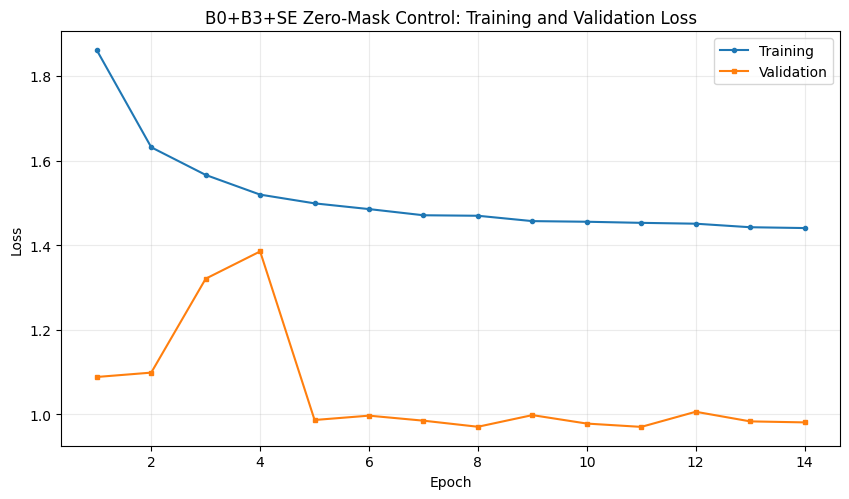

Saved plot: /content/drive/MyDrive/DR_Project/stage3_B3SE_zero_mask_training_control/plots_confusion_matrices/B3_zero_mask_train_val_loss.png


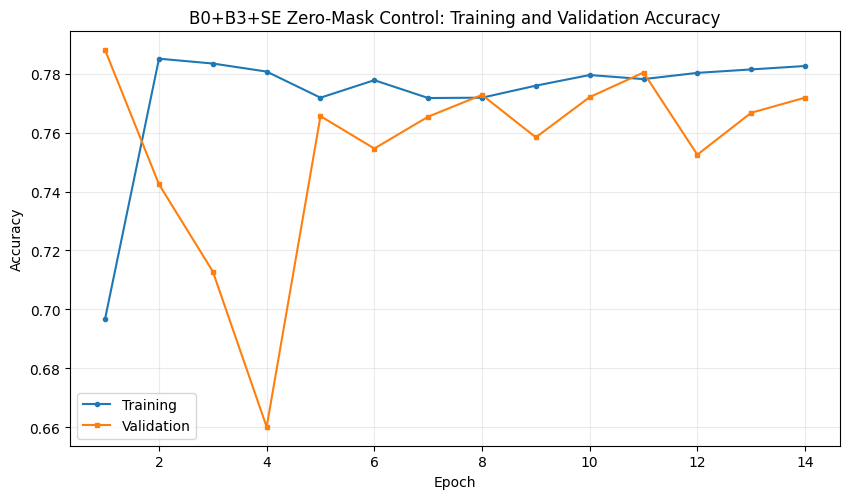

Saved plot: /content/drive/MyDrive/DR_Project/stage3_B3SE_zero_mask_training_control/plots_confusion_matrices/B3_zero_mask_train_val_accuracy.png


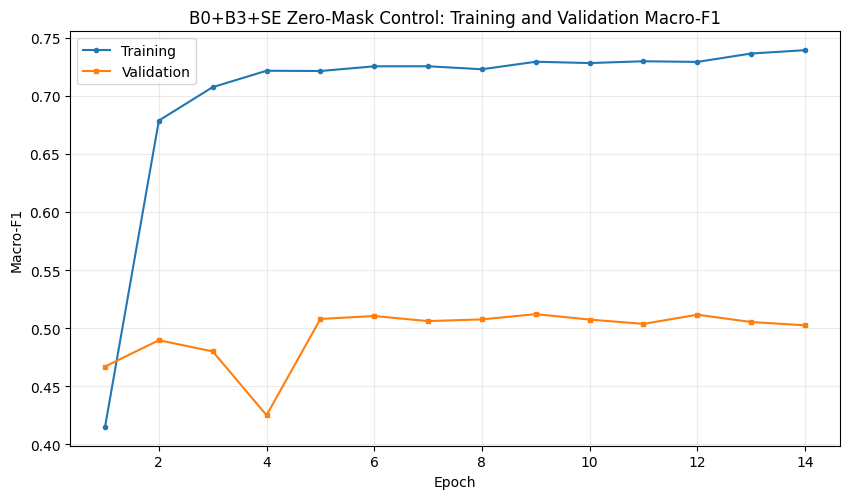

Saved plot: /content/drive/MyDrive/DR_Project/stage3_B3SE_zero_mask_training_control/plots_confusion_matrices/B3_zero_mask_train_val_macro_f1.png


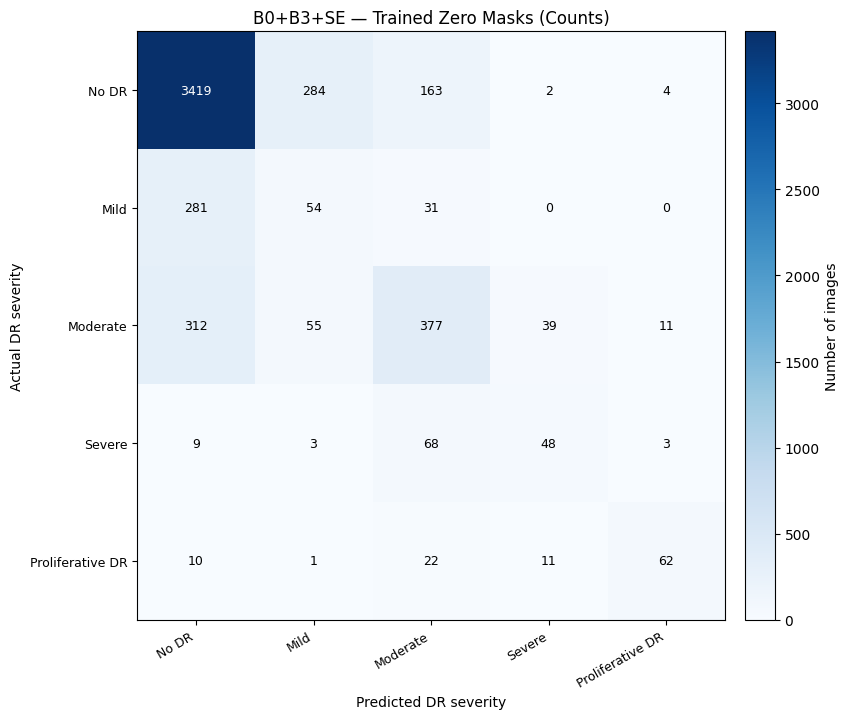

Saved plot: /content/drive/MyDrive/DR_Project/stage3_B3SE_zero_mask_training_control/plots_confusion_matrices/B3_trained_zero_mask_confusion_counts.png


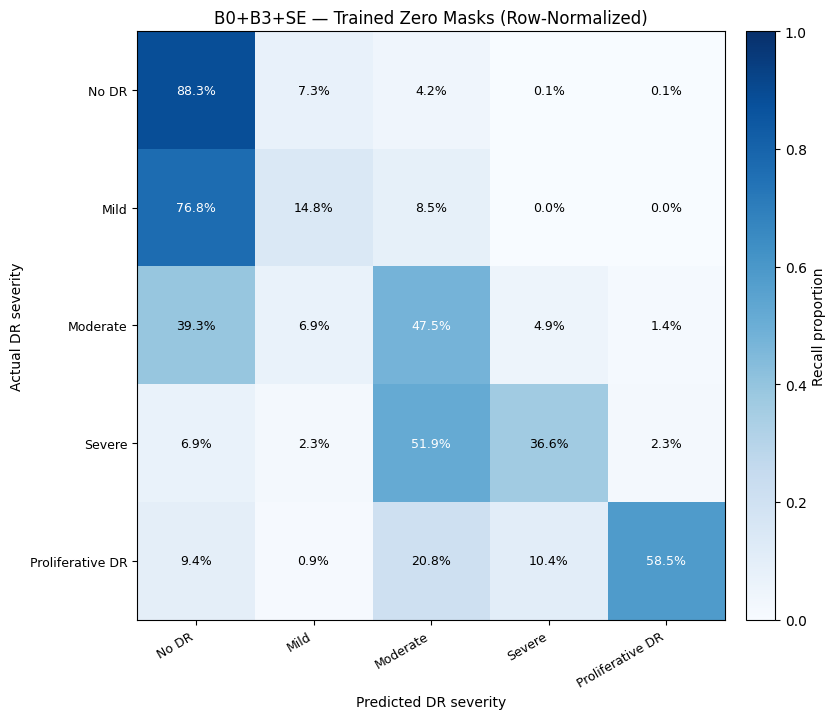

Saved plot: /content/drive/MyDrive/DR_Project/stage3_B3SE_zero_mask_training_control/plots_confusion_matrices/B3_trained_zero_mask_confusion_normalized.png
Saved classification report: /content/drive/MyDrive/DR_Project/stage3_B3SE_zero_mask_training_control/plots_confusion_matrices/B3_trained_zero_mask_classification_report.csv


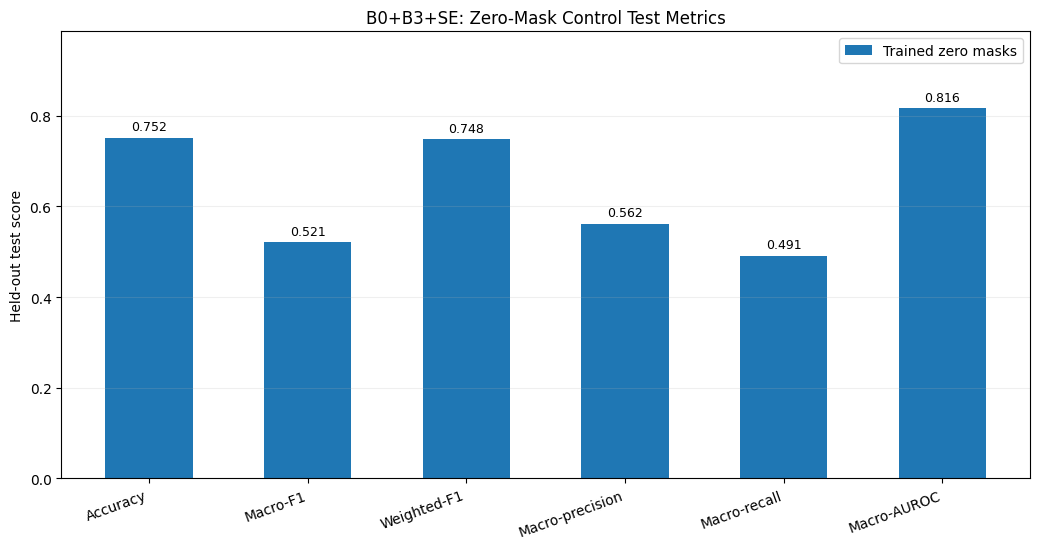

Saved plot: /content/drive/MyDrive/DR_Project/stage3_B3SE_zero_mask_training_control/plots_confusion_matrices/B3_zero_mask_test_metrics.png


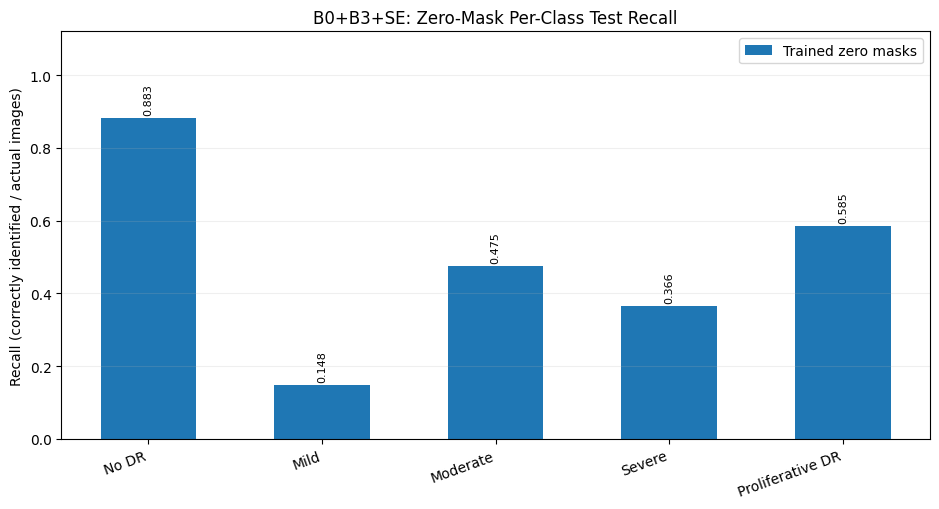

Saved plot: /content/drive/MyDrive/DR_Project/stage3_B3SE_zero_mask_training_control/plots_confusion_matrices/B3_zero_mask_per_class_recall.png

CREATING ZERO-MASK TRAINING PLOTS AND CONFUSION MATRICES: B4


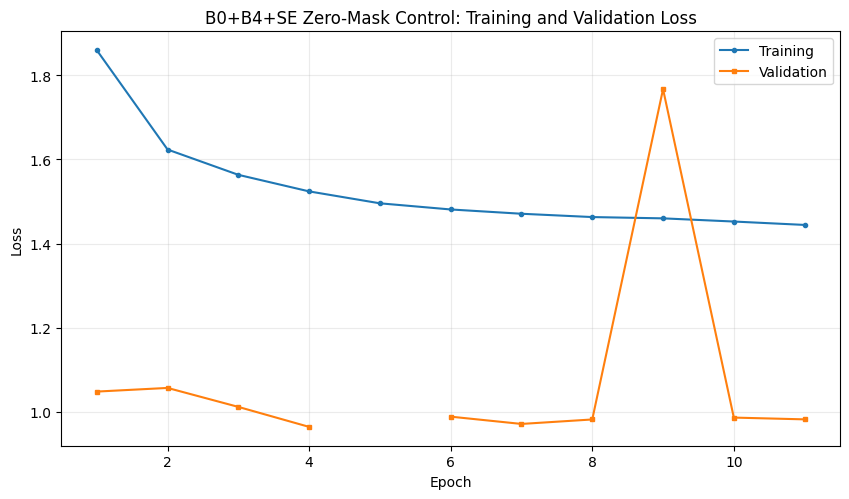

Saved plot: /content/drive/MyDrive/DR_Project/stage3_B3SE_zero_mask_training_control/plots_confusion_matrices/B4_zero_mask_train_val_loss.png


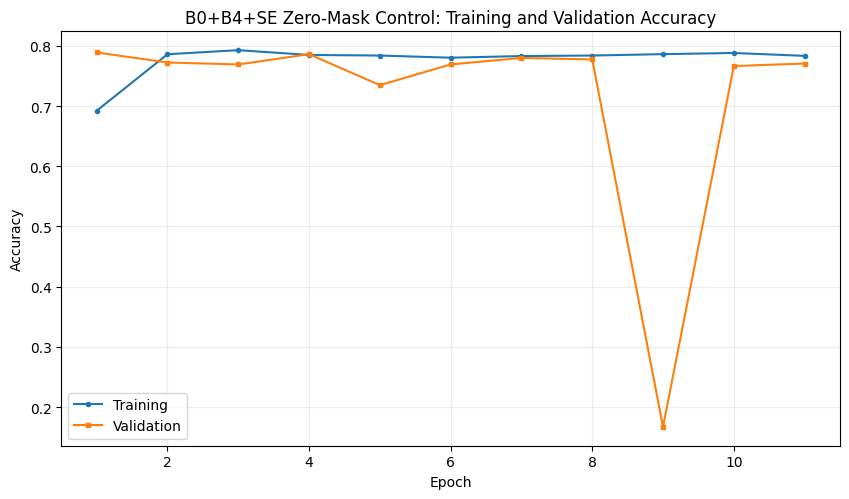

Saved plot: /content/drive/MyDrive/DR_Project/stage3_B3SE_zero_mask_training_control/plots_confusion_matrices/B4_zero_mask_train_val_accuracy.png


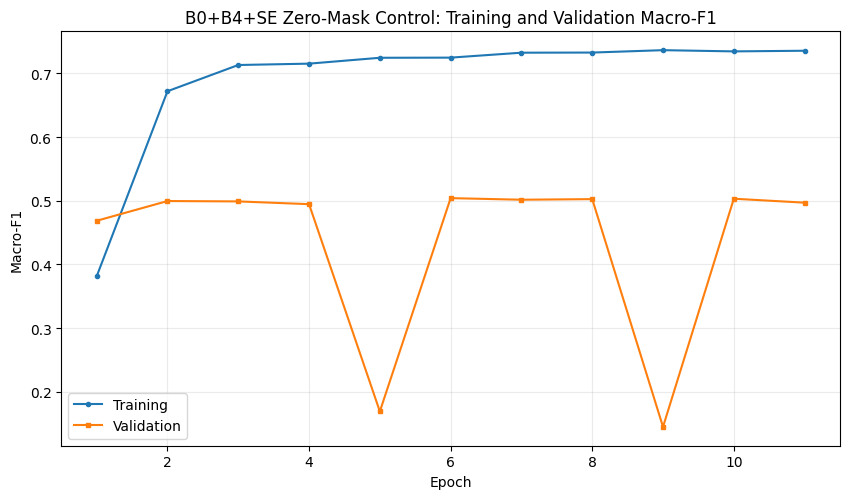

Saved plot: /content/drive/MyDrive/DR_Project/stage3_B3SE_zero_mask_training_control/plots_confusion_matrices/B4_zero_mask_train_val_macro_f1.png


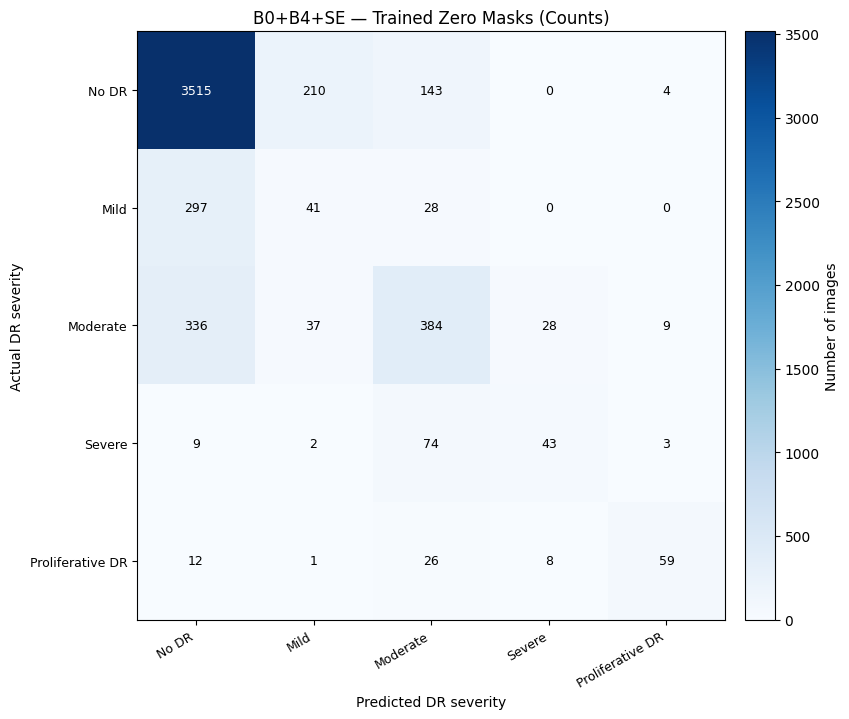

Saved plot: /content/drive/MyDrive/DR_Project/stage3_B3SE_zero_mask_training_control/plots_confusion_matrices/B4_trained_zero_mask_confusion_counts.png


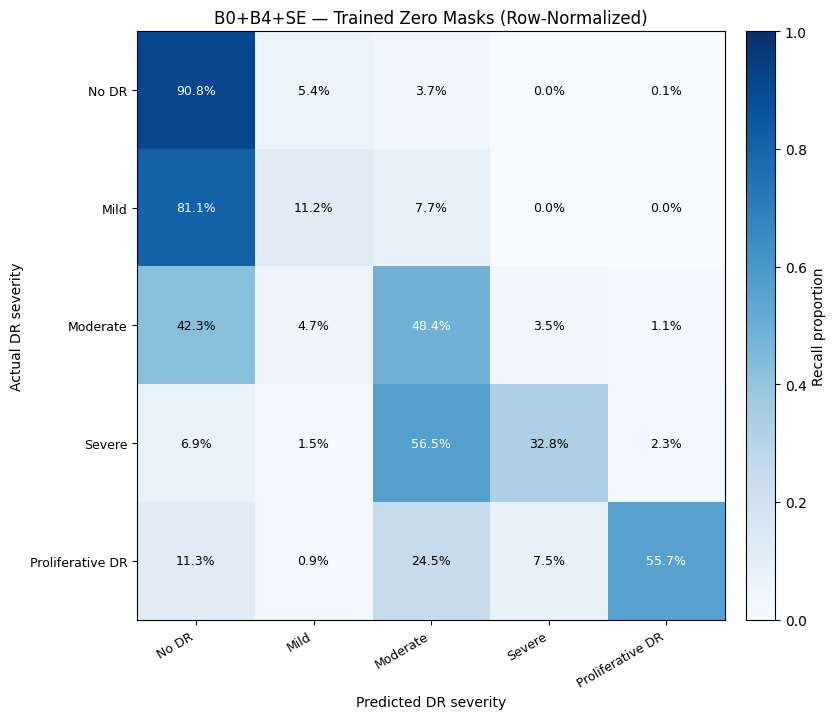

Saved plot: /content/drive/MyDrive/DR_Project/stage3_B3SE_zero_mask_training_control/plots_confusion_matrices/B4_trained_zero_mask_confusion_normalized.png
Saved classification report: /content/drive/MyDrive/DR_Project/stage3_B3SE_zero_mask_training_control/plots_confusion_matrices/B4_trained_zero_mask_classification_report.csv


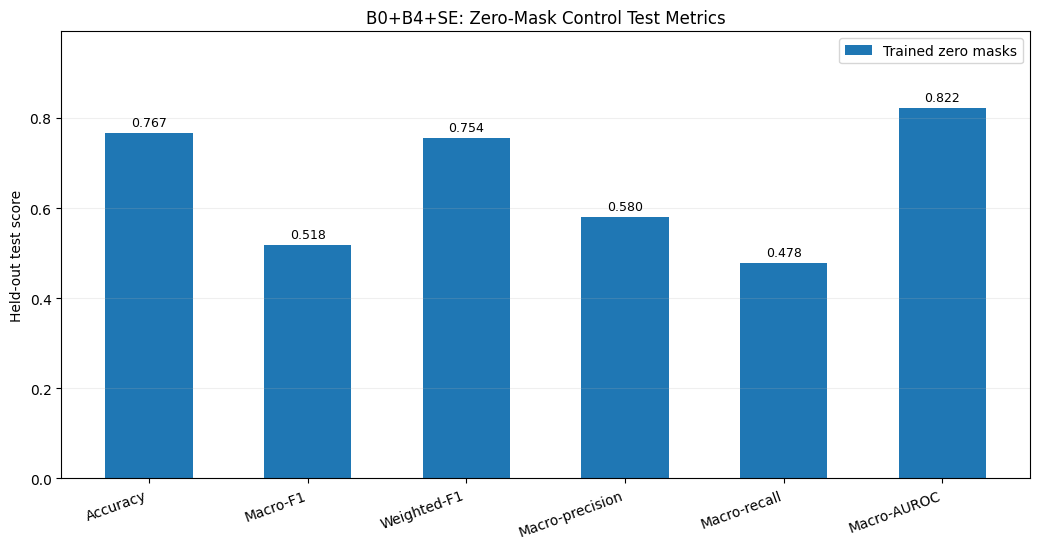

Saved plot: /content/drive/MyDrive/DR_Project/stage3_B3SE_zero_mask_training_control/plots_confusion_matrices/B4_zero_mask_test_metrics.png


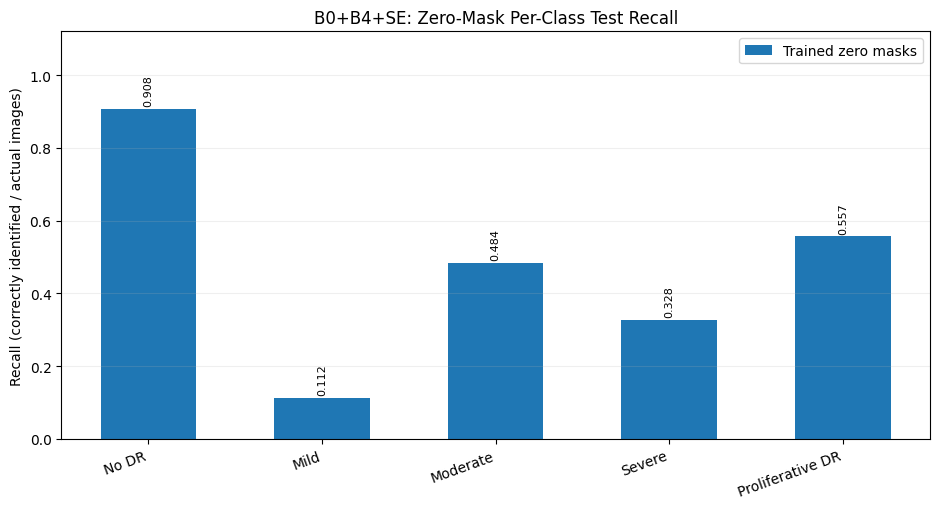

Saved plot: /content/drive/MyDrive/DR_Project/stage3_B3SE_zero_mask_training_control/plots_confusion_matrices/B4_zero_mask_per_class_recall.png

FINISHED B3 AND B4 ZERO-MASK CONTROL PLOTS
Output folder: /content/drive/MyDrive/DR_Project/stage3_B3SE_zero_mask_training_control/plots_confusion_matrices
PNG plots saved: 14
B3_zero_mask_train_val_loss.png
B3_zero_mask_train_val_accuracy.png
B3_zero_mask_train_val_macro_f1.png
B3_trained_zero_mask_confusion_counts.png
B3_trained_zero_mask_confusion_normalized.png
B3_zero_mask_test_metrics.png
B3_zero_mask_per_class_recall.png
B4_zero_mask_train_val_loss.png
B4_zero_mask_train_val_accuracy.png
B4_zero_mask_train_val_macro_f1.png
B4_trained_zero_mask_confusion_counts.png
B4_trained_zero_mask_confusion_normalized.png
B4_zero_mask_test_metrics.png
B4_zero_mask_per_class_recall.png


In [22]:

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report

PLOTS_DIR = Path(DRIVE_COMPARE_DIR) / "plots_confusion_matrices"
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

CLASS_LABELS = [
    "No DR", "Mild", "Moderate", "Severe", "Proliferative DR"
]
CLASS_IDS = list(range(len(CLASS_NAMES)))

assert len(CLASS_NAMES) == 5 and len(CLASS_LABELS) == 5

saved_plots = []


def save_plot(filename):
    target = PLOTS_DIR / filename
    plt.savefig(
        target,
        dpi=220,
        bbox_inches="tight",
        facecolor="white",
    )
    plt.show()
    plt.close()
    saved_plots.append(target)
    print("Saved plot:", target)



def training_plot(
    history, model_name, train_col, val_col,
    title, ylabel, filename
):
    required = {"epoch", train_col, val_col}

    if not required.issubset(history.columns):
        print(
            f"Skipping {model_name} {title}: "
            f"missing columns {sorted(required - set(history.columns))}"
        )
        return

    epochs = pd.to_numeric(history["epoch"], errors="coerce")
    train_values = pd.to_numeric(history[train_col], errors="coerce")
    val_values = pd.to_numeric(history[val_col], errors="coerce")

    fig, ax = plt.subplots(figsize=(8.6, 5.1))

    ax.plot(
        epochs, train_values,
        marker="o", markersize=3,
        label="Training",
    )
    ax.plot(
        epochs, val_values,
        marker="s", markersize=3,
        label="Validation",
    )

    ax.set_title(
        f"B0+{model_name}+SE Zero-Mask Control: {title}"
    )
    ax.set_xlabel("Epoch")
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.25)
    ax.legend()

    fig.tight_layout()
    save_plot(filename)




def draw_confusion_matrix(
    y_true, y_pred, title, filename, normalize=False
):
    counts = confusion_matrix(
        y_true,
        y_pred,
        labels=CLASS_IDS,
    )

    values = counts.astype(float)

    if normalize:
        denominators = np.maximum(
            counts.sum(axis=1, keepdims=True), 1
        )
        values = values / denominators

    fig, ax = plt.subplots(figsize=(9.2, 7.3))

    im = ax.imshow(
        values,
        interpolation="nearest",
        cmap="Blues",
        vmin=0,
        vmax=1 if normalize else None,
    )

    cb = fig.colorbar(im, ax=ax, fraction=0.045, pad=0.025)
    cb.set_label(
        "Recall proportion" if normalize
        else "Number of images"
    )

    ax.set_xticks(CLASS_IDS)
    ax.set_yticks(CLASS_IDS)

    ax.set_xticklabels(
        CLASS_LABELS,
        rotation=30,
        ha="right",
        fontsize=9,
    )
    ax.set_yticklabels(CLASS_LABELS, fontsize=9)

    ax.set_xlabel("Predicted DR severity")
    ax.set_ylabel("Actual DR severity")
    ax.set_title(title)

    threshold = (
        float(np.nanmax(values)) / 2.0
        if values.size else 0
    )

    for i in CLASS_IDS:
        for j in CLASS_IDS:
            value = values[i, j]

            label = (
                f"{value:.1%}"
                if normalize
                else str(int(counts[i, j]))
            )

            ax.text(
                j, i, label,
                ha="center",
                va="center",
                fontsize=9,
                color="white" if value > threshold else "black",
            )

    fig.tight_layout()
    save_plot(filename)




def plot_test_metrics(metrics_csv, model_name):
    metrics = pd.read_csv(metrics_csv)

    expected = [
        "accuracy",
        "macro_f1",
        "weighted_f1",
        "macro_precision",
        "macro_recall",
        "macro_auroc",
    ]

    if not set(expected).issubset(metrics.columns):
        print(
            f"Skipping test metrics for {model_name}: "
            "required metric columns missing"
        )
        return

    if len(metrics) != 1:
        print(
            f"Expected one zero-mask metrics row for {model_name}; "
            f"found {len(metrics)}. Skipping."
        )
        return

    row = metrics.iloc[0]

    positions = np.arange(len(expected))

    fig, ax = plt.subplots(figsize=(10.5, 5.6))

    values = [float(row[key]) for key in expected]

    bars = ax.bar(
        positions,
        values,
        width=0.55,
        label="Trained zero masks",
    )

    ax.bar_label(
        bars,
        fmt="%.3f",
        padding=3,
        fontsize=9,
    )

    ax.set_xticks(positions)
    ax.set_xticklabels(
        [
            "Accuracy",
            "Macro-F1",
            "Weighted-F1",
            "Macro-precision",
            "Macro-recall",
            "Macro-AUROC",
        ],
        rotation=20,
        ha="right",
    )

    ax.set_ylim(
        0,
        min(1.1, max(0.75, max(values) + 0.17)),
    )

    ax.set_ylabel("Held-out test score")
    ax.set_title(
        f"B0+{model_name}+SE: Zero-Mask Control Test Metrics"
    )

    ax.legend(loc="upper right")
    ax.grid(axis="y", alpha=0.2)

    fig.tight_layout()

    save_plot(
        f"{model_name}_zero_mask_test_metrics.png"
    )




def plot_per_class_recall(metrics_csv, model_name):
    metrics = pd.read_csv(metrics_csv)

    recall_columns = [
        f"recall_{name}" for name in CLASS_NAMES
    ]

    if not set(recall_columns).issubset(metrics.columns):
        print(
            f"Skipping per-class recall for {model_name}: "
            "recall columns missing"
        )
        return

    if len(metrics) != 1:
        print(
            f"Expected one zero-mask metrics row for {model_name}; "
            f"found {len(metrics)}. Skipping."
        )
        return

    row = metrics.iloc[0]

    positions = np.arange(len(CLASS_NAMES))

    fig, ax = plt.subplots(figsize=(9.5, 5.2))

    values = [
        float(row[key]) for key in recall_columns
    ]

    bars = ax.bar(
        positions,
        values,
        width=0.55,
        label="Trained zero masks",
    )

    ax.bar_label(
        bars,
        fmt="%.3f",
        padding=2,
        fontsize=8,
        rotation=90,
    )

    ax.set_xticks(positions)
    ax.set_xticklabels(
        CLASS_LABELS,
        rotation=20,
        ha="right",
    )

    ax.set_ylim(0, 1.12)

    ax.set_ylabel(
        "Recall (correctly identified / actual images)"
    )

    ax.set_title(
        f"B0+{model_name}+SE: Zero-Mask Per-Class Test Recall"
    )

    ax.legend(loc="upper right")
    ax.grid(axis="y", alpha=0.2)

    fig.tight_layout()

    save_plot(
        f"{model_name}_zero_mask_per_class_recall.png"
    )




for model_name in ("B3", "B4"):

    print("\n" + "=" * 85)
    print(
        f"CREATING ZERO-MASK TRAINING PLOTS "
        f"AND CONFUSION MATRICES: {model_name}"
    )
    print("=" * 85)



    history_path = (
        Path(DRIVE_COMPARE_DIR)
        / f"stage3_{model_name}_history.csv"
    )

    if history_path.is_file():

        history = pd.read_csv(history_path)

        training_plot(
            history,
            model_name,
            "train_loss",
            "val_loss",
            "Training and Validation Loss",
            "Loss",
            f"{model_name}_zero_mask_train_val_loss.png",
        )

        training_plot(
            history,
            model_name,
            "train_accuracy",
            "val_accuracy",
            "Training and Validation Accuracy",
            "Accuracy",
            f"{model_name}_zero_mask_train_val_accuracy.png",
        )

        training_plot(
            history,
            model_name,
            "train_macro_f1",
            "val_macro_f1",
            "Training and Validation Macro-F1",
            "Macro-F1",
            f"{model_name}_zero_mask_train_val_macro_f1.png",
        )

    else:
        print("Training history not found:", history_path)
        print(
            "Run the B3/B4 zero-mask training cell "
            "first to generate training curves."
        )



    pred_path = (
        Path(DRIVE_COMPARE_DIR)
        / f"{model_name}_zero_mask_control_test_predictions.csv"
    )

    metrics_path = (
        Path(DRIVE_COMPARE_DIR)
        / f"{model_name}_zero_mask_control_test_metrics.csv"
    )

    if not pred_path.is_file():
        print("Zero-mask test predictions not found:", pred_path)
        print(
            "Run the zero-mask control test evaluation cell first."
        )
        continue

    predictions = pd.read_csv(pred_path)

    required_cols = {
        "true_label",
        "zero_mask_prediction",
    }

    if not required_cols.issubset(predictions.columns):
        raise ValueError(
            f"Missing columns in {pred_path}: "
            f"{required_cols - set(predictions.columns)}"
        )

    y_true = predictions["true_label"].to_numpy(dtype=int)

    y_pred = predictions[
        "zero_mask_prediction"
    ].to_numpy(dtype=int)

    if len(y_true) != 5269:
        raise ValueError(
            f"Expected 5269 test images for {model_name}; "
            f"found {len(y_true)}"
        )

    if not np.isin(y_true, CLASS_IDS).all():
        raise ValueError(
            f"Unexpected true class ID for {model_name}."
        )

    if not np.isin(y_pred, CLASS_IDS).all():
        raise ValueError(
            f"Unexpected predicted class ID for {model_name}."
        )



    cm_title = (
        f"B0+{model_name}+SE — Trained Zero Masks"
    )

    draw_confusion_matrix(
        y_true,
        y_pred,
        cm_title + " (Counts)",
        f"{model_name}_trained_zero_mask_confusion_counts.png",
        normalize=False,
    )

    draw_confusion_matrix(
        y_true,
        y_pred,
        cm_title + " (Row-Normalized)",
        f"{model_name}_trained_zero_mask_confusion_normalized.png",
        normalize=True,
    )



    report = classification_report(
        y_true,
        y_pred,
        labels=CLASS_IDS,
        target_names=CLASS_NAMES,
        zero_division=0,
        output_dict=True,
    )

    report_path = (
        PLOTS_DIR
        / f"{model_name}_trained_zero_mask_classification_report.csv"
    )

    pd.DataFrame({
        key: (
            val if isinstance(val, dict)
            else {"accuracy": val}
        )
        for key, val in report.items()
    }).T.to_csv(report_path)

    print("Saved classification report:", report_path)



    if metrics_path.is_file():

        plot_test_metrics(metrics_path, model_name)

        plot_per_class_recall(metrics_path, model_name)

    else:
        print("Zero-mask test metrics CSV unavailable:", metrics_path)




print("\n" + "=" * 85)
print("FINISHED B3 AND B4 ZERO-MASK CONTROL PLOTS")
print("=" * 85)

print("Output folder:", PLOTS_DIR)
print("PNG plots saved:", len(saved_plots))

for path in saved_plots:
    print(path.name)
